<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/NQEDR_AdversarialRobustness_Li2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NQE-DR (dual-regularised nonlinear quantum encoding) against FGSM and noise: Li et al. (2026) step by step

**Paper.** YaoChong Li, XinXin Deng, RuiQing Xu, WenShan Xu and Ri-Gui Zhou, *Dual-regularized nonlinear quantum encoding for adversarial robustness in quantum machine learning*, New Journal of Physics **28**, 014511 (2026). DOI [10.1088/1367-2630/ae32a8](https://doi.org/10.1088/1367-2630/ae32a8). Authors' code: [github.com/stars-art/quantum-robust](https://github.com/stars-art/quantum-robust), used here at the pinned commit `8fbade6295c52e5845d3bb25c85024ceccb98460`.

**What this notebook does.** A quantum classifier that reads a data point through rotation gates can be fooled by tiny input changes (the FGSM attack moves every feature by `eps` in the direction that increases the loss). The paper proposes **NQE-DR**: (1) squash every feature with a sigmoid and also square it, (2) encode the two results with an `RZ` and an `RY` gate per qubit, (3) entangle all qubit pairs with CNOTs, (4) apply one trainable `RY` per qubit, (5) read out the observable `Z (x) X`, and (6) train with a loss that also punishes large parameters and large input-gradients ("dual regularisation"). The notebook

1. fetches the authors' repository at a pinned commit and tells you exactly what in it can and cannot be reused (the circuit module is missing and the training script does not even parse);
2. rebuilds the data sets (Circle, Gaussian mixture, Breast Cancer, MNIST 0 vs 1), explores them, and draws every quantum circuit that is executed;
3. implements NQE-DR and the paper's comparison encodings (angle, hardware-efficient, amplitude, ZZ feature map, data re-uploading) in PennyLane, training with exact input-gradients;
4. re-creates the paper's Tables 1 to 4 and Figures 4 to 8 (accuracy, noise and FGSM robustness, Lipschitz estimate, scaling of the Lipschitz value, ablation) and compares every number with the paper, claim by claim;
5. adds classical baselines on identical inputs and a sensitivity study that asks why the paper's Circle accuracy is not reached.

**How to run.** Open in Colab (`Runtime > Run all`, CPU runtime is enough, no GPU or quantum hardware). `FAST_MODE = True` (1 seed, 40 epochs) takes a few minutes; `FAST_MODE = False` (the setting saved in this notebook) follows the paper's 200 epochs with 3 seeds (2 for MNIST) and takes about 45 minutes on a laptop CPU. If a session restart is requested after the install cell, run all again.

**What you get at the end.** Tables and plots for every experiment of the paper, an explicit verdict ("reproduced", "not reached here", "exceeded", "cannot be checked") for each claim that can be tested, and a critical reading of what the evidence supports.

## The paper in one page

**Problem.** Quantum neural networks (QNNs) can be fooled by small perturbations of the input. The paper asks which *encoding* of classical data into a circuit, together with which *training regularisers*, gives a more robust classifier.

**Decision.** Binary classification (class 0 / class 1). Prediction is the sign of the expectation value `f(x) = <psi(x)| Z_0 X_1 |psi(x)>` (Eq. 17 and 18), and the loss is a cross-entropy.

**Method (NQE-DR, Eq. 9).** `NQE-DR(x) = M o U_trainable o U_ent o E o T (x)`:
* `T`: `x_sig = sigmoid(x)` (Eq. 10), `x_sqr = x_sig * x_sig` (Eq. 11);
* `E`: per qubit `RY(x_sqr) RZ(x_sig)` (Eq. 13 and 14), one qubit per feature;
* `U_ent`: CNOT between every pair `i < j` (Eq. 15);
* `U_trainable`: one `RY(phi_i)` per qubit, `phi_i ~ U(0, pi)` (Eq. 16);
* `M = Z (x) X (x) I ...` (Eq. 17).

**Dual regularisation (Eq. 19 to 21).** `L_total = L_task + lambda1 * ||Theta||_F^2 + lambda2 * ||grad_x f(x)||_2^2`, with `lambda1 = 0.01`, `lambda2 = 0.2` (chosen by 5-fold cross-validation, per the paper). The second term bounds the model's Lipschitz constant, so an attacker needs a larger perturbation to change the label.

**Data.** Circle (points in `[-1,1]^2`, radius `sqrt(2/pi)`), Gaussian mixture (10 features, 3 modes, 1000 samples, 700/300), Breast Cancer Wisconsin (569 samples, 400/169), MNIST digits 0 vs 1 (12 665 train / 2 115 test, PCA to 4 features). Features are scaled to `[0, 1]`. Training: Adam, learning rate 0.1, 200 epochs; PennyLane.

**Attacks.** Random uniform noise of strength `eps` and FGSM of strength `delta`, both clipped back to the valid feature range, for strengths 0.1 to 1.0 (Table 2) and 0.1, 0.3, 0.5, 0.7 (Tables 3 and 4).

**Claims to test.**
1. Clean accuracy of NQE-DR: Circle 0.978, Gaussian 0.985, Breast Cancer 0.958, and NQE-DR beats HEE, AE and AmE on all three (Table 1).
2. NQE-DR keeps higher accuracy than HEE, AE, AmE under noise and FGSM at (almost) every strength (Table 2).
3. NQE-DR has the lowest empirical Lipschitz value (9.5), AmE the highest (Fig. 7).
4. The Lipschitz value stays substantial for `n <= 12` qubits and `d <= 8` layers and decays slowly with both (Fig. 8).
5. On MNIST 0 vs 1, NQE-DR reaches 0.969 clean and is the best of six encodings (NQE-DR, data re-uploading, ZZ feature map, HEE, AE, AmE) under attack (Table 3).
6. Ablation on Circle: removing `T`, the full entanglement or the regularisers lowers accuracy and robustness (Table 4).

## What follows the paper and what had to be chosen

The paper gives the model in prose, but the authors' repository does not contain it (see section 0). Everything the text leaves open is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Framework | PennyLane (version not stated), Poetry, Dask | PennyLane 0.45.1 for the circuits, drawings and reference results; a small PyTorch state-vector simulator that interprets **the same gate list** for fast training, asserted equal to the PennyLane QNode (outputs and input-gradients, section 3). Dask is not needed. |
| Qubits | not stated per data set; implicitly one per feature (Eq. 14) | one per feature, at least 2 (the observable needs qubits 0 and 1): Circle 2, others 4 |
| Gaussian mixture and Breast Cancer dimension | 10 and 30 features (Sec. 4.1); "dimensionality reduction" for Breast Cancer, none stated for Gaussian | **PCA to 4 features** for both (fitted on the training split), the same reduction the paper uses for MNIST. A 10 to 30 qubit model with exact second-order autodiff does not fit the memory of a Colab CPU. |
| Input range | features "normalised to [0,1]" (Sec. 4.1); `train_nqedr.py` mentions `(0, 2*pi)` | MinMax to `[0, 1]` fitted on the training split, test values clipped; the `[0, 2*pi]` and z-score alternatives are tested in the sensitivity study |
| Trainable parameters | `n` RY angles (Eq. 16) | exactly that (`LAYERS = 1`); the repository's tensors `weights[n_layer, n_qubit, x_dim, x_dim]` describe a different model and are not used |
| Output / loss | softmax over class outputs; cross-entropy; no scale given | one scalar `f in [-1, 1]`; class 1 if `f > 0`; binary cross-entropy on `p = sigmoid(s f)` with **`s = 10`**. The authors' linear link `p = (f + 1) / 2` (`s = None`) makes the small-range model collapse to the majority class (shown in section 4b); `s` is picked on pooled validation accuracy, not on test data. |
| Gradient regulariser | `lambda2 * ||grad_x f||_2` in Eq. 20 is written as a sum of squares | squared L2 norm of the exact input gradient, averaged over the batch (Eq. 20 and 21 as printed) |
| Baselines "AE, HEE, AmE" | "all schemes employ the same PQC framework" | same measurement, same trainable `RY` layer, same loss **including the dual regularisers**; AE and AmE use the full CNOT network, HEE nearest-neighbour CNOTs; AE angle = feature (Eq. 2) |
| ZZ feature map, data re-uploading (MNIST) | Eq. 3 and Eq. 4, depths not stated | ZZ gates on a linear chain, one repetition; re-uploading with 3 layers of `RY(x)`, `RY(phi)RZ(psi)`, CNOT chain |
| Optimiser | Adam, lr 0.1, 200 epochs | same, full batch for the small data sets; MNIST uses random mini-batches of 1 024 samples per step (200 steps), 2 seeds |
| `lambda1`, `lambda2` | 0.01 and 0.2, "selected via 5-fold CV" | the paper's values are used everywhere; in the full run a small 3-fold grid search on Breast Cancer is shown for information |
| Noise attack | uniform noise per component, symbol lost in the PDF text | `U(-eps, eps)` per component, clipped to `[0, 1]`, averaged over 5 draws |
| FGSM | `delta = eps * sign(grad_x L)` | the same, gradient of the BCE loss, white-box, clipped to `[0, 1]` |
| Lipschitz value (Fig. 7) | mean of local constants over 50 validation samples | mean of `||grad_x f||_2` over (up to) 50 validation samples, exact autodiff |
| Depth `d` (Fig. 8) | "circuit depths 3,4,5,6,8" | `d` repetitions of [full CNOT network, trainable RY layer] after a single encoding |
| Seeds | ensemble (repository: 5) | `N_SEEDS` seeds (1 in FAST mode, 3 in the full run), mean and standard deviation reported |
| Validation split | last 20% of the training part (repository) | the same; used to pick the best epoch (parameters of the best validation accuracy are restored) |

In [1]:
# Install (pinned to the versions this notebook was tested with). Colab already ships numpy, pandas,
# scikit-learn, matplotlib and torch; on a machine that already has PennyLane 0.45.1 nothing is reinstalled.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
def _needs_install():
    try:
        import pennylane, torch, pyarrow, PIL, sklearn   # noqa: F401
        return pennylane.__version__ != "0.45.1"
    except Exception:
        return True
if IN_COLAB or _needs_install():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "pyarrow", "pillow", "huggingface_hub"])
    print("Installed. If Colab asks for a runtime restart, restart and run all cells again.")
else:
    print("Required packages already present.")

Required packages already present.


In [2]:
# ---------------------------------------------------------------- configuration (every tunable constant)
SEED = 42                      # master seed
FAST_MODE = False              # True: a few minutes (1 seed, 40 epochs). False: paper budgets (3 seeds, 200 epochs), about 1 hour on CPU
IBM_TOKEN = ""                 # not used: this paper needs no quantum hardware
DATA_DIR = "qc067_data"        # downloads (authors' repo, MNIST) are cached here

LAM1, LAM2 = 0.01, 0.2         # dual-regularisation strengths (paper, Sec. 4.1)
LR = 0.1                       # Adam learning rate (paper)
LOGIT_SCALE = 10.0             # CHOICE: readout p = sigmoid(10 f).  None = authors' linear link p = (f+1)/2, which collapses to the majority class (section 4b)
SCALE_GRID = [None, 3.0, 10.0, 30.0]   # candidates compared on VALIDATION accuracy in section 4b
N_QUBITS_MAX = 4               # CHOICE: PCA dimension for Gaussian / Breast Cancer / MNIST (paper: 4 for MNIST)
LAYERS = 1                     # number of [encode, entangle, RY] blocks; the paper's model has exactly one
N_NOISE_DRAWS = 5              # random-noise attack is averaged over this many draws
EPS_LEVELS = [round(0.1 * k, 1) for k in range(1, 11)]   # Table 2 strengths
EPS_MNIST = [0.1, 0.3, 0.5, 0.7]                          # Tables 3 and 4 strengths

if FAST_MODE:
    N_SEEDS, EPOCHS, MNIST_STEPS, MNIST_BATCH = 1, 40, 40, 512
    SCALE_NS, SCALE_DS, SCALE_SAMPLES = [4, 6, 8], [3, 5, 8], 4
    SENS_EPOCHS, SENS_SEEDS, RUN_CV = 40, 1, False
    LS_SEEDS, LS_EPOCHS, MNIST_SEEDS = 1, 50, 1
else:
    N_SEEDS, EPOCHS, MNIST_STEPS, MNIST_BATCH = 3, 200, 200, 1024
    SCALE_NS, SCALE_DS, SCALE_SAMPLES = [4, 6, 8, 10, 12], [3, 4, 5, 6, 8], 6
    SENS_EPOCHS, SENS_SEEDS, RUN_CV = 150, 2, True
    LS_SEEDS, LS_EPOCHS, MNIST_SEEDS = 1, 100, 2
print(f"FAST_MODE={FAST_MODE}  seeds={N_SEEDS}  epochs={EPOCHS}  MNIST steps={MNIST_STEPS} (batch {MNIST_BATCH})")

FAST_MODE=False  seeds=3  epochs=200  MNIST steps=200 (batch 1024)


In [3]:
import os, io, sys, math, time, zipfile, subprocess, importlib.util, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import KFold
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_breast_cancer
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.25})

DATA = Path(DATA_DIR); DATA.mkdir(exist_ok=True)

# Hugging Face token (only needed for gated data sets; MNIST is public, so None works).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

## 0. The authors' repository: what can be reused

The paper's data-availability statement points to `github.com/stars-art/quantum-robust`. We clone it at the pinned commit and inspect it before relying on anything. We reuse only what is correct and matches the paper's text (the Circle generator `circle()`, the hyper-parameter grid of `train_nqedr.py`, the BCE loss and the R1/R2 definitions); everything else is rewritten.

In [4]:
REPO_URL = "https://github.com/stars-art/quantum-robust"
PINNED_COMMIT = "8fbade6295c52e5845d3bb25c85024ceccb98460"
REPO = DATA / "quantum-robust"

def fetch_repo():
    if (REPO / "data.py").exists():
        return "cached"
    try:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO)], check=True, capture_output=True, timeout=300)
        subprocess.run(["git", "-C", str(REPO), "checkout", "-q", PINNED_COMMIT], check=True, capture_output=True)
        return "git clone"
    except Exception as exc:                                   # no git, or network policy: fall back to the archive
        print("git clone failed (", type(exc).__name__, ") -> downloading the archive of the pinned commit")
        r = requests.get(f"{REPO_URL}/archive/{PINNED_COMMIT}.zip", timeout=300); r.raise_for_status()
        zipfile.ZipFile(io.BytesIO(r.content)).extractall(DATA)
        (DATA / f"quantum-robust-{PINNED_COMMIT}").rename(REPO)
        return "zip archive"

how = fetch_repo()
try:
    head = subprocess.run(["git", "-C", str(REPO), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
except Exception:
    head = ""
print("repository obtained via:", how, "| HEAD:", head or "(no git metadata)")
if head:
    assert head == PINNED_COMMIT, "repository is not at the pinned commit"

print("\nfiles:", sorted(p.name for p in REPO.iterdir() if p.is_file()))
print("circuit.py present (imported by train_nqedr.py as `from .circuit import nqedr_encoding`):", (REPO / "circuit.py").exists())
try:
    compile((REPO / "train_nqedr.py").read_text(encoding="utf-8"), "train_nqedr.py", "exec")
    print("train_nqedr.py parses")
except SyntaxError as e:
    print(f"train_nqedr.py does not parse: SyntaxError '{e.msg}' at line {e.lineno} (an unterminated docstring in preprocess_data)")
src = (REPO / "train_nqedr.py").read_text(encoding="utf-8")
print("an FGSM / attack implementation in the .py files:", any("def fgsm" in p.read_text(encoding="utf-8").lower() or "def attack" in p.read_text(encoding="utf-8").lower() for p in REPO.glob("*.py")))
for key in ["n_layer", "n_qubit", "n_ensemble", "learning_rate", "n_epoch", "early_stopping_patience", "scaling_range", "cv_folds", "lambda1_candidates", "lambda2_candidates"]:
    line = [l for l in src.splitlines() if l.startswith(key)]
    print("  train_nqedr.py:", line[0] if line else key + " (not found)")

repository obtained via: git clone | HEAD: 8fbade6295c52e5845d3bb25c85024ceccb98460

files: ['README.md', 'data.py', 'data_types.py', 'file.py', 'plot_loss_acc.py', 'train_nqedr.py']
circuit.py present (imported by train_nqedr.py as `from .circuit import nqedr_encoding`): False
train_nqedr.py does not parse: SyntaxError 'invalid character '·' (U+00B7)' at line 44 (an unterminated docstring in preprocess_data)
an FGSM / attack implementation in the .py files: False
  train_nqedr.py: n_layer = 3
  train_nqedr.py: n_qubit = 3
  train_nqedr.py: n_ensemble = 5
  train_nqedr.py: learning_rate = 0.01
  train_nqedr.py: n_epoch = 200
  train_nqedr.py: early_stopping_patience = 15
  train_nqedr.py: scaling_range = (0, 2 * np.pi)
  train_nqedr.py: cv_folds = 5  # 5折交叉验证
  train_nqedr.py: lambda1_candidates = [0.001, 0.01, 0.05, 0.1, 0.2]  # 参数正则化强度 λ1
  train_nqedr.py: lambda2_candidates = [0.1, 0.2, 0.3, 0.5, 0.7]      # 梯度正则化强度 λ2


In [5]:
# Load the authors' data.py as a module.  Its circle() calls np.array(..., requires_grad=False), which only exists in
# pennylane.numpy, while the file imports plain numpy -> we point the module's `np` at pennylane.numpy (same code, no edit).
import pennylane as qml
from pennylane import numpy as pnp
spec = importlib.util.spec_from_file_location("qr_data", REPO / "data.py")
qr_data = importlib.util.module_from_spec(spec); spec.loader.exec_module(qr_data)
qr_data.np = pnp

# (a) authors' Gaussian mixture loader: check it against the paper's description (Mode 1 -> 0, Modes 2-3 -> 1)
Xg_auth, yg_auth = qr_data.load_gaussian_mixture_dataset(SEED)
print("authors' load_gaussian_mixture_dataset:", Xg_auth.shape, "label counts", dict(zip(*np.unique(yg_auth, return_counts=True))),
      "-> paper describes three modes of ~333 points with Mode 1 vs the rest, i.e. ~333 / ~667")
# (b) authors' Breast Cancer loader: PCA(n_components=0.95) on UNSCALED features
Xb_auth, yb_auth = qr_data.load_breast_cancer_dataset(SEED)
print("authors' load_breast_cancer_dataset ->", Xb_auth.shape, "(unscaled features: one component already holds >95% of the variance, so a 1-qubit input)")

authors' load_gaussian_mixture_dataset: (1000, 10) label counts {tensor(0, requires_grad=True): np.int64(111), tensor(1, requires_grad=True): np.int64(889)} -> paper describes three modes of ~333 points with Mode 1 vs the rest, i.e. ~333 / ~667
authors' load_breast_cancer_dataset -> (569, 1) (unscaled features: one component already holds >95% of the variance, so a 1-qubit input)


**Findings about the repository** (all printed above):

* `circuit.py` (providing `nqedr_encoding`, the actual NQE-DR circuit) is **not in the repository**, and `train_nqedr.py` does not parse (unterminated docstring), so the authors' training code cannot be run. There is no FGSM or noise-attack code, no baseline encodings (HEE/AE/AmE/ZZ/DRU) and no plotting data.
* The training script's weights `weights[n_layer, n_qubit, x_dim, x_dim]` and `biases[n_layer, n_qubit, x_dim]` are a data re-uploading model with learned linear maps (it looks inherited from another code base), not the `n`-parameter circuit of the paper's Eq. 16.
* `data.py`: `circle()` is correct once `np` points to `pennylane.numpy` (we use it). The Gaussian loader labels only the inner half of Mode 1 as class 0 (`make_gaussian_quantiles` returns two classes per call), which gives roughly 111 vs 889 points instead of the paper's Mode 1 vs Modes 2 and 3; the Breast Cancer loader applies PCA to unscaled features and therefore keeps a single component. We follow the **paper's text** for both and record the discrepancy.
* What we do take from the repository: the Circle generator, the `lambda1`/`lambda2` candidate grids, the BCE loss on `(f + 1) / 2`, the definitions of R1 and R2, the validation split (last 20% of the training part), `learning_rate`/`n_epoch` conventions, and `n_ensemble = 5` as the guide for repeated runs.

## 1. Data

Four data sets, each prepared as in the paper's Section 4.1, all downloaded or generated here:

* **Circle**: 1 000 points uniform in `[-1, 1]^2`, label "inside the circle of radius `sqrt(2/pi)`" (generated by the authors' `circle()`); inside is class 0, outside class 1 (paper's binarisation). 700 train / 300 test.
* **Gaussian mixture**: 1 000 points in 10 dimensions, three Gaussian modes with means `+2`, `-2`, `0` (unit variance, 333/333/334 points); Mode 1 is class 0 and Modes 2 and 3 are class 1. 700 / 300. (Generated from the paper's description; see section 0.)
* **Breast Cancer Wisconsin (UCI, shipped with scikit-learn)**: 569 samples, 30 features; benign is class 0, malignant class 1. Shuffled, 400 train / 169 test.
* **MNIST digits 0 versus 1**: from the public Hugging Face mirror `ylecun/mnist` (no token needed); 12 665 train / 2 115 test, as in the paper.

The last 20% of each training part is a validation set used only to pick the best epoch (as in the authors' `data.py`).

In [6]:
def split_val(n_train):
    n_val = int(n_train * 0.2)
    return n_train - n_val                        # index where the validation block starts (authors' data.py: last 20%)

RAW = {}

# ---- Circle (authors' circle(), unchanged)
pnp.random.seed(SEED)
Xc, yc = qr_data.circle(1000)
Xc, yc = np.asarray(Xc, dtype=float), 1 - np.asarray(yc, dtype=int)         # paper: inside -> 0, outside -> 1
RAW["circle"] = dict(X=Xc, y=yc, fam=yc, fam_names=["inside circle (0)", "outside circle (1)"], n_train=700,
                     features=["x1", "x2"], title="Circle")

# ---- Gaussian mixture: three modes, Mode 1 -> 0, Modes 2-3 -> 1
rng = np.random.default_rng(SEED)
sizes, means = [333, 333, 334], [2.0, -2.0, 0.0]
Xg = np.vstack([rng.normal(m, 1.0, (s, 10)) for m, s in zip(means, sizes)])
mode = np.repeat([0, 1, 2], sizes)
perm = rng.permutation(len(Xg)); Xg, mode = Xg[perm], mode[perm]
RAW["gaussian"] = dict(X=Xg, y=(mode != 0).astype(int), fam=mode, fam_names=["Mode 1 (mean +2)", "Mode 2 (mean -2)", "Mode 3 (mean 0)"],
                       n_train=700, features=[f"g{i}" for i in range(10)], title="Gaussian mixture")

# ---- Breast Cancer Wisconsin
bc = load_breast_cancer()
Xb, yb = bc.data, 1 - bc.target                                              # sklearn: 1 = benign -> paper: benign 0, malignant 1
perm = np.random.default_rng(SEED).permutation(len(Xb)); Xb, yb = Xb[perm], yb[perm]
RAW["breast_cancer"] = dict(X=Xb, y=yb, fam=yb, fam_names=["benign (0)", "malignant (1)"], n_train=400,
                            features=[str(f) for f in bc.feature_names], title="Breast Cancer Wisconsin")

# ---- MNIST 0 vs 1 (public mirror; pixels scaled to [0, 1])
def load_mnist01():
    from PIL import Image
    try:
        from huggingface_hub import hf_hub_download
        out = {}
        for split in ["train", "test"]:
            p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                                local_dir=str(DATA / "hf_mnist"), token=HF_TOKEN)
            df = pd.read_parquet(p); df = df[df["label"].isin([0, 1])]
            imgs = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).reshape(len(df), -1) / 255.0
            out[split] = (imgs, df["label"].to_numpy())
        return out["train"], out["test"], "Hugging Face ylecun/mnist"
    except Exception as exc:
        print("Hugging Face download failed (", type(exc).__name__, ") -> OpenML fallback")
        from sklearn.datasets import fetch_openml
        mn = fetch_openml("mnist_784", version=1, as_frame=False, data_home=str(DATA / "openml"))
        X, y = mn.data / 255.0, mn.target.astype(int)
        tr, te = slice(0, 60000), slice(60000, 70000)
        sel = lambda s: (lambda m: (X[s][m], y[s][m]))(np.isin(y[s], [0, 1]))
        return sel(tr), sel(te), "OpenML mnist_784"

(Xm_tr, ym_tr), (Xm_te, ym_te), mn_src = load_mnist01()
rngm = np.random.default_rng(SEED); pm = rngm.permutation(len(Xm_tr))
Xm_tr, ym_tr = Xm_tr[pm], ym_tr[pm]
RAW["mnist01"] = dict(X=np.vstack([Xm_tr, Xm_te]), y=np.r_[ym_tr, ym_te], fam=np.r_[ym_tr, ym_te], fam_names=["digit 0", "digit 1"],
                      n_train=len(Xm_tr), features=[f"pixel_{i}" for i in range(784)], title="MNIST 0 vs 1")
print("MNIST source:", mn_src, "| train", Xm_tr.shape, "test", Xm_te.shape)
for k, r in RAW.items():
    print(f"{k:14s} X {r['X'].shape}  train {r['n_train']}  test {len(r['X']) - r['n_train']}  class counts {np.bincount(r['y']).tolist()}")

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

MNIST source: Hugging Face ylecun/mnist | train (12665, 784) test (2115, 784)
circle         X (1000, 2)  train 700  test 300  class counts [491, 509]
gaussian       X (1000, 10)  train 700  test 300  class counts [333, 667]
breast_cancer  X (569, 30)  train 400  test 169  class counts [357, 212]
mnist01        X (14780, 784)  train 12665  test 2115  class counts [6903, 7877]


## 2. Preprocessing (every transform is fitted on the fitting part of the training split only)

* Circle: MinMax to `[0, 1]`.
* Gaussian mixture: PCA to 4 components, then MinMax to `[0, 1]`.
* Breast Cancer: standardisation, PCA to 4 components (the paper reduces the 30 features; the authors' unscaled PCA would keep one), MinMax.
* MNIST: PCA of the 784 pixels to 4 components (as in the paper), MinMax.

Validation and test values are transformed with the training fit and clipped to `[0, 1]`; these `[0, 1]` values are what the encoders see (and what the attacks perturb and clip).

In [7]:
from sklearn.pipeline import Pipeline
import torch

def make_pipeline(name):
    steps = {"circle": [MinMaxScaler()],
             "gaussian": [PCA(n_components=N_QUBITS_MAX, random_state=SEED), MinMaxScaler()],
             "breast_cancer": [StandardScaler(), PCA(n_components=N_QUBITS_MAX, random_state=SEED), MinMaxScaler()],
             "mnist01": [PCA(n_components=N_QUBITS_MAX, random_state=SEED), MinMaxScaler()]}[name]
    return Pipeline([(f"s{i}", s) for i, s in enumerate(steps)])

DS = {}
for name, r in RAW.items():
    X, y, fam, n_tr = r["X"], r["y"], r["fam"], r["n_train"]
    n_fit = split_val(n_tr)
    sl = dict(fit=slice(0, n_fit), val=slice(n_fit, n_tr), te=slice(n_tr, len(X)))
    pipe = make_pipeline(name).fit(X[sl["fit"]])
    t = lambda part: torch.tensor(np.clip(pipe.transform(X[sl[part]]), 0.0, 1.0))
    d = dict(pipe=pipe, d=t("fit").shape[1], raw={k: X[s] for k, s in sl.items()}, fam={k: fam[s] for k, s in sl.items()})
    for part, key in [("fit", "fit"), ("val", "va"), ("te", "te")]:
        d["x" + key] = t(part); d["y" + key] = torch.tensor(y[sl[part]]).double()
    DS[name] = d
    print(f"{name:14s} model input dimension d={d['d']}  fit {tuple(d['xfit'].shape)}  val {tuple(d['xva'].shape)}  test {tuple(d['xte'].shape)}  "
          f"range [{d['xfit'].min():.2f}, {d['xfit'].max():.2f}]")

circle         model input dimension d=2  fit (560, 2)  val (140, 2)  test (300, 2)  range [0.00, 1.00]
gaussian       model input dimension d=4  fit (560, 4)  val (140, 4)  test (300, 4)  range [0.00, 1.00]
breast_cancer  model input dimension d=4  fit (320, 4)  val (80, 4)  test (169, 4)  range [0.00, 1.00]


mnist01        model input dimension d=4  fit (10132, 4)  val (2533, 4)  test (2115, 4)  range [0.00, 1.00]


## Dataset Exploration and Visualisation

For each of the four real data sets: shape, feature names, original label values and class counts; a bar chart of the real classes (original families first, then the binary label the model uses); and a 2-D scatter of the **real training observations coloured by their ground-truth label**: first the raw PCA coordinates (PCA fitted on the training split), then the first two model inputs scaled to `[0, 1]` (what the NQE-DR encoder receives), then the same coordinates scaled to `[0, pi]` (the rotation angle of angle encoding with a full half-turn). No synthetic stand-ins are used; the Circle and Gaussian sets are the paper's own synthetic benchmarks.

Circle: full data shape (1000, 2) (train 700 incl. 20% validation, test 300)
feature names (2): ['x1', 'x2'] 
original label values and counts: {'inside circle (0)': 491, 'outside circle (1)': 509}
binary label used by the model (0/1) counts: [491, 509]


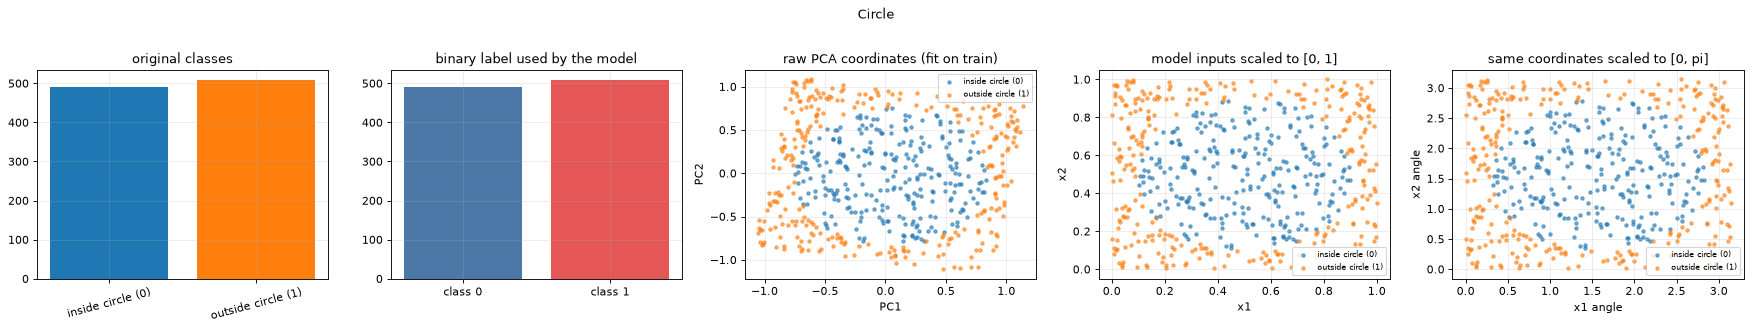

Gaussian mixture: full data shape (1000, 10) (train 700 incl. 20% validation, test 300)
feature names (10): ['g0', 'g1', 'g2', 'g3', 'g4', 'g5', 'g6', 'g7'] ...
original label values and counts: {'Mode 1 (mean +2)': 333, 'Mode 2 (mean -2)': 333, 'Mode 3 (mean 0)': 334}
binary label used by the model (0/1) counts: [333, 667]


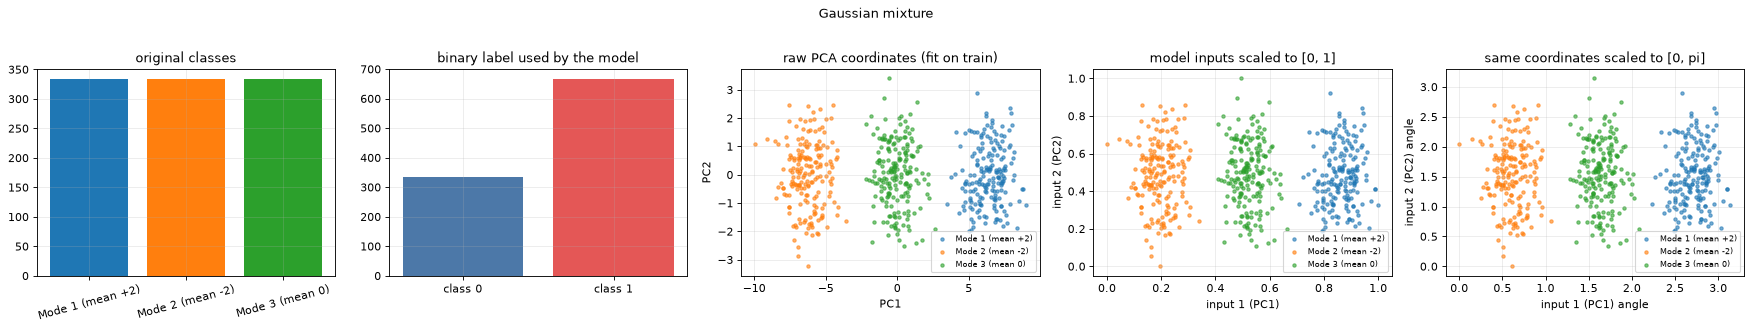

Breast Cancer Wisconsin: full data shape (569, 30) (train 400 incl. 20% validation, test 169)
feature names (30): ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points'] ...
original label values and counts: {'benign (0)': 357, 'malignant (1)': 212}
binary label used by the model (0/1) counts: [357, 212]


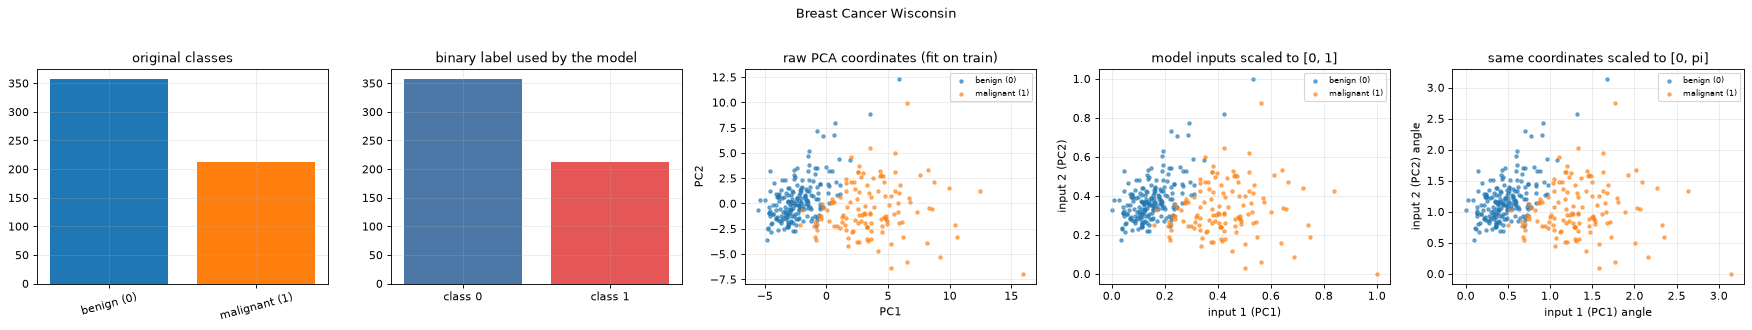

MNIST 0 vs 1: full data shape (14780, 784) (train 12665 incl. 20% validation, test 2115)
feature names (784): ['pixel_0', 'pixel_1', 'pixel_2', 'pixel_3', 'pixel_4', 'pixel_5', 'pixel_6', 'pixel_7'] ...
original label values and counts: {'digit 0': 6903, 'digit 1': 7877}
binary label used by the model (0/1) counts: [6903, 7877]


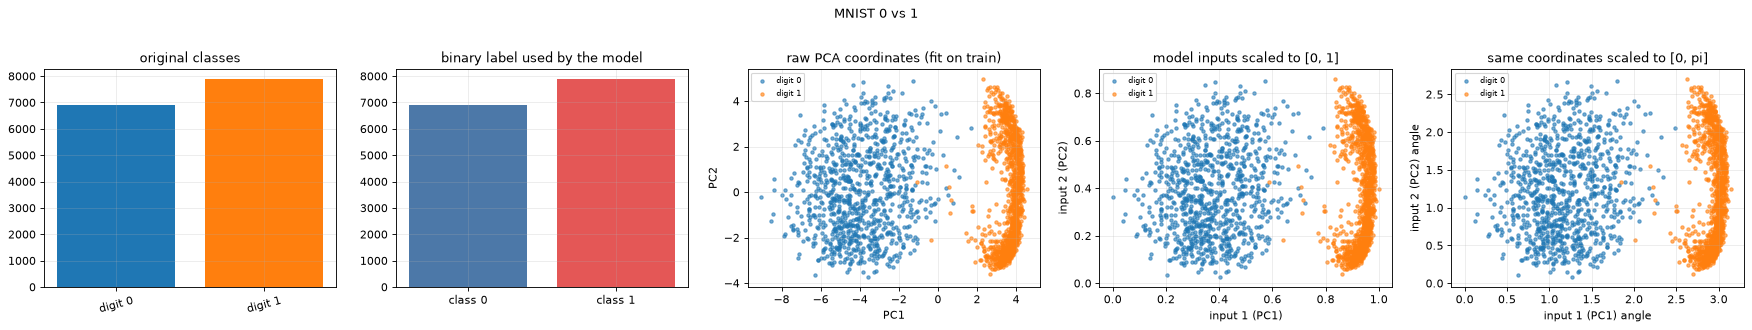

In [8]:
def explore(name):
    r, d = RAW[name], DS[name]
    X = r["X"]
    print("=" * 100)
    print(f"{r['title']}: full data shape {X.shape} (train {r['n_train']} incl. 20% validation, test {len(X) - r['n_train']})")
    feats = r["features"]
    print(f"feature names ({len(feats)}):", feats[:8], "..." if len(feats) > 8 else "")
    fam_all = np.r_[d["fam"]["fit"], d["fam"]["val"], d["fam"]["te"]]
    print("original label values and counts:", {r["fam_names"][int(k)]: int(v) for k, v in zip(*np.unique(fam_all, return_counts=True))})
    print("binary label used by the model (0/1) counts:", np.bincount(r["y"]).tolist())
    fig, ax = plt.subplots(1, 5, figsize=(22, 4))
    cols = plt.cm.tab10(np.arange(len(r["fam_names"])))
    k, c = np.unique(fam_all, return_counts=True)
    ax[0].bar([r["fam_names"][int(i)] for i in k], c, color=cols[k.astype(int)]); ax[0].set_title("original classes"); ax[0].tick_params(axis="x", rotation=15)
    kb, cb = np.unique(r["y"], return_counts=True)
    ax[1].bar(["class 0", "class 1"], cb, color=["#4C78A8", "#E45756"]); ax[1].set_title("binary label used by the model")
    pre = ([StandardScaler()] if name == "breast_cancer" else []) + [PCA(n_components=2, random_state=SEED)]
    p2 = Pipeline([(f"s{i}", s) for i, s in enumerate(pre)]).fit(d["raw"]["fit"])
    P = p2.transform(d["raw"]["fit"]); fam = d["fam"]["fit"]
    sub = np.random.default_rng(SEED).permutation(len(P))[:2000]                 # at most 2000 points per plot
    def scat(a, Z, title, xl, yl):
        for j, nm in enumerate(r["fam_names"]):
            m = fam[sub] == j
            a.scatter(Z[sub][m, 0], Z[sub][m, 1], s=9, alpha=0.6, color=cols[j], label=nm)
        a.set_title(title); a.set_xlabel(xl); a.set_ylabel(yl); a.legend(fontsize=7)
    scat(ax[2], P, "raw PCA coordinates (fit on train)", "PC1", "PC2")
    Zs = d["xfit"].numpy()[:, :2]
    lab = ("x1", "x2") if name == "circle" else ("input 1 (PC1)", "input 2 (PC2)")
    scat(ax[3], Zs, "model inputs scaled to [0, 1]", *lab)
    scat(ax[4], Zs * np.pi, "same coordinates scaled to [0, pi]", lab[0] + " angle", lab[1] + " angle")
    fig.suptitle(r["title"], y=1.02); plt.tight_layout(); plt.show()

for name in DS:
    explore(name)

## 3. The models: one gate list, two interpreters

`encoder_ansatz` below is the single description of every circuit (NQE-DR, its ablations, and the baselines AE, HEE, AmE, ZZ feature map, data re-uploading). Two *backends* interpret it:

* `PLBackend` emits PennyLane gates inside a QNode. This is the circuit that is **drawn** in the next section and used as the reference.
* `TorchBackend` is a ~40-line batched state-vector simulator in PyTorch used for training and attacks, because PennyLane's second-order autodiff (needed for the input-gradient regulariser) is about 10 to 30 times slower on a CPU.

A test cell in the next section asserts that both give identical `<Z_0 X_1>` values and identical input-gradients for every architecture.

In [9]:
import time, math
import numpy as np
import torch
import torch.nn.functional as F
import pennylane as qml

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)           # CHOICE: tiny tensors; 1 thread is fastest here (more threads only add contention)

# ----------------------------------------------------------------------------------------------
# 1. ONE gate list for every model.  It is written once (encoder_ansatz) against an abstract
#    "backend"; two backends interpret it:
#       PLBackend    -> PennyLane gates inside a QNode   (circuit drawings, reference results)
#       TorchBackend -> a small batched state-vector simulator in PyTorch (fast training / attacks)
#    A test cell later asserts that both backends return the same <Z0 X1> and the same input gradients.
# ----------------------------------------------------------------------------------------------
ENCODINGS_NQE = ("NQE-DR", "NQE-DR-T", "NQE-DR-Uent", "NQE-DR-Ulayered", "NQE-DR-R")

def n_wires_for(enc, d):
    """Number of qubits an encoding needs for d input features (always >= 2 so that M = Z0 X1 exists)."""
    if enc == "AmE":
        return max(2, math.ceil(math.log2(max(d, 2))))      # amplitude encoding: log2(d) qubits
    return max(2, d)                                         # one feature per qubit

def params_per_block(enc, n):
    if enc == "DRU":
        return 2 * n
    if enc in ("NQE-DR-Ulayered",):
        return 2 * n
    return n

def n_blocks_for(enc, layers):
    return DRU_LAYERS if enc == "DRU" else layers

DRU_LAYERS = 3     # CHOICE: depth of the data re-uploading baseline (the paper does not give it)

def _cnot_full(B, n):
    for i in range(n):
        for j in range(i + 1, n):
            B.cnot(i, j)                                      # Eq. (15): CNOT_ij for all pairs i<j

def _cnot_chain(B, n):
    for i in range(n - 1):
        B.cnot(i, i + 1)

def _col(x, i):
    return x[..., i]

def encoder_ansatz(B, enc, x, phi, n, d, layers=1):
    """Gate sequence of every model in the paper.  x: (batch, d) or (d,) in [0, 1];  phi: (blocks, params_per_block)."""
    blocks = n_blocks_for(enc, layers)
    for l in range(blocks):
        p = phi[l]
        if enc in ENCODINGS_NQE:
            for i in range(n):
                xi = _col(x, i)
                if enc == "NQE-DR-T":                         # ablation: raw features, no sigmoid / squaring
                    xsig, xsqr = xi, xi
                else:
                    xsig = torch.sigmoid(xi)                   # Eq. (10)  T, stage 1
                    xsqr = xsig * xsig                         # Eq. (11)  T, stage 2
                B.rz(xsig, i)                                  # Eq. (13)  U_i = RY(x_sqr) RZ(x_sig)
                B.ry(xsqr, i)
            if enc == "NQE-DR-Uent":
                _cnot_chain(B, n)                              # ablation: adjacent qubits only
            elif enc == "NQE-DR-Ulayered":
                for i in range(n):                             # ablation: layered hardware-efficient ansatz
                    B.ry(p[i], i)
                _cnot_chain(B, n)
                for i in range(n):
                    B.ry(p[n + i], i)
                _cnot_chain(B, n)
                continue
            else:
                _cnot_full(B, n)                               # Eq. (15)
            for i in range(n):
                B.ry(p[i], i)                                  # Eq. (16)
        elif enc == "NQE-DR-deep":
            # used only by the scalability study (Fig. 8): ONE encoding, then `layers` repetitions of
            # [fully connected CNOT network, trainable RY layer]  (circuit depth grows, data are not re-uploaded)
            if l == 0:
                for i in range(n):
                    xsig = torch.sigmoid(_col(x, i))
                    B.rz(xsig, i)
                    B.ry(xsig * xsig, i)
            _cnot_full(B, n)
            for i in range(n):
                B.ry(p[i], i)
        elif enc in ("AE", "AE-pi"):
            scale = math.pi if enc == "AE-pi" else 1.0
            for i in range(n):
                B.ry(scale * _col(x, i), i)                    # Eq. (2)
            _cnot_full(B, n)                                   # CHOICE: same PQC (full CNOT + trainable RY) as NQE-DR
            for i in range(n):
                B.ry(p[i], i)
        elif enc == "HEE":
            for i in range(n):
                B.ry(_col(x, i), i)
            _cnot_chain(B, n)                                  # local (nearest-neighbour) entanglement
            for i in range(n):
                B.ry(p[i], i)
        elif enc == "AmE":
            if l == 0:
                amp = x if x.ndim > 1 else x[None]
                amp = F.pad(amp, (0, 2 ** n - d))
                amp = amp / (amp.norm(dim=-1, keepdim=True) + 1e-12)       # Eq. (1)
                B.stateprep(amp if x.ndim > 1 else amp[0], n)
            _cnot_full(B, n)
            for i in range(n):
                B.ry(p[i], i)
        elif enc == "ZZF":
            for i in range(n - 1):                             # Eq. (3): ZZ_ij(x_i x_j) on a linear chain
                B.cnot(i, i + 1)
                B.rz(_col(x, i) * _col(x, i + 1), i + 1)
                B.cnot(i, i + 1)
            for i in range(n):
                B.ry(_col(x, i), i)
            for i in range(n):
                B.rz(_col(x, i), i)
            for i in range(n):
                B.ry(p[i], i)
        elif enc == "DRU":
            for i in range(n):                                 # Eq. (4): alternate encoding and variational layers
                B.ry(_col(x, i), i)
            for i in range(n):
                B.ry(p[i], i)
                B.rz(p[n + i], i)
            _cnot_chain(B, n)
        else:
            raise ValueError(enc)

In [10]:
class PLBackend:
    """Interprets the gate list as PennyLane operations (inside a QNode)."""
    def ry(self, a, w): qml.RY(a, wires=w)
    def rz(self, a, w): qml.RZ(a, wires=w)
    def cnot(self, c, t): qml.CNOT(wires=[c, t])
    def stateprep(self, amp, n): qml.StatePrep(amp, wires=range(n), normalize=False)

class TorchBackend:
    """Batched state-vector simulator.  Wire 0 is the most significant bit (same convention as PennyLane)."""
    _perm_cache = {}
    def __init__(self, n, batch=None):
        self.n, self.batch = n, batch
        self.st = None
        self.pending = None                                   # fused CNOT permutation
        self.B = 1 if batch is None else batch

    def _init(self):
        st = torch.zeros(self.B, 2 ** self.n, dtype=torch.complex128)
        st[:, 0] = 1.0
        self.st = st

    def _flush(self):
        if self.pending is not None:
            self.st = self.st[:, self.pending]
            self.pending = None

    def _angle(self, a):
        a = torch.as_tensor(a)
        return a.reshape(-1) if a.ndim else a.reshape(1)       # (B,) or (1,)

    def _apply1(self, U, w):                                   # U: (B or 1, 2, 2) complex
        self._flush()
        if self.st is None: self._init()
        v = self.st.reshape(self.B, 2 ** w, 2, 2 ** (self.n - w - 1))
        self.st = torch.einsum("bij,bljr->blir", U.expand(self.B, 2, 2), v).reshape(self.B, -1)

    def ry(self, a, w):
        a = self._angle(a); c, s = torch.cos(a / 2), torch.sin(a / 2)
        U = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)
        self._apply1(U, w)

    def rz(self, a, w):
        a = self._angle(a)
        z = torch.zeros_like(a)
        U = torch.stack([torch.stack([torch.polar(torch.ones_like(a), -a / 2), z.to(torch.complex128)], -1),
                         torch.stack([z.to(torch.complex128), torch.polar(torch.ones_like(a), a / 2)], -1)], -2)
        self._apply1(U, w)

    def cnot(self, c, t):
        if self.st is None: self._init()
        key = (self.n, c, t)
        if key not in TorchBackend._perm_cache:
            idx = torch.arange(2 ** self.n)
            cb = (idx >> (self.n - 1 - c)) & 1
            TorchBackend._perm_cache[key] = idx ^ (cb << (self.n - 1 - t))
        p = TorchBackend._perm_cache[key]
        self.pending = p if self.pending is None else self.pending[p]   # (psi[p1])[p2] = psi[p1[p2]]

    def stateprep(self, amp, n):
        amp = amp if amp.ndim == 2 else amp[None]
        self.B = amp.shape[0]
        self.st = amp.to(torch.complex128)

    def expval_ZX(self):
        """<Z_0 X_1> = sum_i conj(psi_i) (-1)^{bit0(i)} psi_{i xor flip1}."""
        self._flush()
        n = self.n
        idx = torch.arange(2 ** n)
        sign = 1.0 - 2.0 * ((idx >> (n - 1)) & 1).to(torch.float64)
        flip = idx ^ (1 << (n - 2))
        return (self.st.conj() * (self.st[:, flip] * sign)).sum(-1).real

def build_qnode(enc, d, layers=1):
    n = n_wires_for(enc, d)
    dev = qml.device("default.qubit", wires=n)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, phi):
        encoder_ansatz(PLBackend(), enc, x, phi, n, d, layers)
        return qml.expval(qml.PauliZ(0) @ qml.PauliX(1))        # Eq. (17): M = Z (qubit 0) x X (qubit 1) x I...
    circuit.n_wires = n
    return circuit

class Model:
    """Binary classifier f(x) = <Z0 X1> in [-1, 1]; class 1 iff f(x) > 0 (CHOICE)."""
    def __init__(self, enc, d, layers=1, seed=0, engine="torch"):
        self.enc, self.d, self.layers, self.engine = enc, d, layers, engine
        self.n = n_wires_for(enc, d)
        self.blocks = n_blocks_for(enc, layers)
        g = torch.Generator().manual_seed(seed)
        shape = (self.blocks, params_per_block(enc, self.n))
        self.phi = (math.pi * torch.rand(shape, generator=g)).requires_grad_(True)   # phi_i ~ U(0, pi), Sec. 3.1
        self._qnode = None

    @property
    def qnode(self):
        if self._qnode is None:
            self._qnode = build_qnode(self.enc, self.d, self.layers)
        return self._qnode

    def n_params(self):
        return self.phi.numel()

    def f(self, x, engine=None):
        engine = engine or self.engine
        if engine == "pennylane":
            return self.qnode(x, self.phi)
        be = TorchBackend(self.n, None if x.ndim == 1 else x.shape[0])
        encoder_ansatz(be, self.enc, x, self.phi, self.n, self.d, self.layers)
        return be.expval_ZX() if x.ndim > 1 else be.expval_ZX()[0]

    def predict(self, x):
        with torch.no_grad():
            return (self.f(x) > 0).long()

### Loss, training and attacks

* `total_loss` is Eq. 21: BCE + `lambda1 * ||phi||^2` + `lambda2 * mean_x ||grad_x f||^2`. The input gradient is taken with `create_graph=True` so that the gradient penalty itself is differentiated with respect to the circuit parameters.
* `train` runs Adam and restores the parameters with the best validation accuracy.
* `noise_attack` and `fgsm_attack` follow Section 4.2; `lipschitz_estimate` is the mean of `||grad_x f||_2` over 50 validation samples.

In [11]:
# LOGIT_SCALE (set in the configuration cell): None -> p = (f + 1) / 2 as in the authors' train_nqedr.py; a number s -> p = sigmoid(s * f).
def task_loss(fx, y):
    """Binary cross-entropy.  Link from the expectation value f in [-1, 1] to a probability:
    linear p = (f + 1) / 2 as in the authors' train_nqedr.py, or p = sigmoid(s f) when LOGIT_SCALE = s."""
    p = ((fx + 1) / 2) if LOGIT_SCALE is None else torch.sigmoid(LOGIT_SCALE * fx)
    p = p.clamp(1e-8, 1 - 1e-8)
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

def input_grad(model, x, create_graph=False, engine=None):
    """Exact d f / d x for every sample (samples are independent, so one backward of the sum suffices)."""
    x = x.clone().requires_grad_(True)
    fx = model.f(x, engine)
    (g,) = torch.autograd.grad(fx.sum(), x, create_graph=create_graph)
    return fx, g

def total_loss(model, x, y, lam1, lam2):
    """Eq. (21): L_total = L_task + lam1 ||Theta||_F^2 + lam2 ||grad_x f(x)||_2^2 (averaged over the batch)."""
    xg = x.clone().requires_grad_(True)
    fx = model.f(xg)
    l_task = task_loss(fx, y)
    r1 = lam1 * (model.phi ** 2).sum()                                           # Eq. (19)
    if lam2 > 0:
        (g,) = torch.autograd.grad(fx.sum(), xg, create_graph=True)
        r2 = lam2 * (g ** 2).sum(dim=1).mean()                                   # Eq. (20)
    else:
        r2 = torch.zeros(())
    return l_task + r1 + r2, l_task.detach(), r1.detach(), r2.detach()

def train(model, xtr, ytr, xva, yva, lam1, lam2, epochs, lr=0.1, patience=None, batch=None, seed=0, verbose=0):
    """Adam on L_total.  batch=None: full-batch steps (as in the paper's small data sets);
    batch=k: each step uses k random training samples (used for MNIST, 12 665 images)."""
    opt = torch.optim.Adam([model.phi], lr=lr)
    gen = torch.Generator().manual_seed(seed)
    best = (-1.0, model.phi.detach().clone(), 0)
    hist = {"loss": [], "task": [], "r1": [], "r2": [], "train_acc": [], "val_acc": []}
    bad = 0
    for ep in range(epochs):
        opt.zero_grad()
        if batch is not None and batch < len(xtr):
            idx = torch.randperm(len(xtr), generator=gen)[:batch]
            xb, yb = xtr[idx], ytr[idx]
        else:
            xb, yb = xtr, ytr
        loss, lt, r1, r2 = total_loss(model, xb, yb, lam1, lam2)
        loss.backward()
        opt.step()
        with torch.no_grad():
            tra = (model.predict(xb) == yb.long()).double().mean().item()
            vaa = (model.predict(xva) == yva.long()).double().mean().item()
        for k, v in zip(["loss", "task", "r1", "r2", "train_acc", "val_acc"], [loss.item(), lt.item(), r1.item(), r2.item(), tra, vaa]):
            hist[k].append(v)
        if vaa > best[0]:
            best = (vaa, model.phi.detach().clone(), ep); bad = 0
        else:
            bad += 1
            if patience and bad >= patience:
                break
        if verbose and ep % verbose == 0:
            print(f"  ep {ep:3d} loss {loss.item():.4f} task {lt.item():.4f} R1 {r1.item():.4f} R2 {r2.item():.4f} train {tra:.3f} val {vaa:.3f}")
    with torch.no_grad():
        model.phi.copy_(best[1])                                   # restore the best-validation parameters
    return hist, best[2]

def accuracy(model, x, y):
    return (model.predict(x) == y.long()).double().mean().item()

def noise_attack(x, eps, gen):
    """Uniform noise in [-eps, eps] per component, clipped to the valid range [0, 1] (Sec. 4.2)."""
    return (x + (2 * torch.rand(x.shape, generator=gen) - 1) * eps).clamp(0, 1)

def fgsm_attack(model, x, y, eps):
    """FGSM: x_adv = clip(x + eps * sign(grad_x L(f(x), y)), 0, 1)."""
    xg = x.clone().requires_grad_(True)
    loss = task_loss(model.f(xg), y) * len(x)               # sum over samples -> per-sample gradients
    (g,) = torch.autograd.grad(loss, xg)
    return (x + eps * g.sign()).clamp(0, 1).detach()

def lipschitz_estimate(model, x, n_samples=50):
    """Mean local Lipschitz constant ||grad_x f(x)||_2 over n_samples inputs (exact autodiff, Sec. 4.2)."""
    _, g = input_grad(model, x[:n_samples])
    return g.norm(dim=1).mean().item()

## Quantum Circuit Architecture

Each drawing below is produced by `qml.draw_mpl` on the **PennyLane QNode built from the same `encoder_ansatz` gate list** that the training simulator interprets. The first drawing is the paper's NQE-DR circuit for the Circle data (2 qubits); the others use 4 qubits (the dimension used for Gaussian, Breast Cancer and MNIST). Printed for every circuit: qubits, depth, gate count and trainable parameters.

Assumptions where the paper omits details: the measurement is `Z` on qubit 0 and `X` on qubit 1 only (Eq. 17); in the baselines the same measurement and the same trainable `RY` layer are used; HEE uses a nearest-neighbour CNOT chain; the ZZ feature map uses one repetition with a linear chain; the data re-uploading model has 3 layers; the amplitude-encoding circuit needs `log2(d)` qubits (padding with zeros). Drawings show gate names; the numeric angles come from the data and parameters.

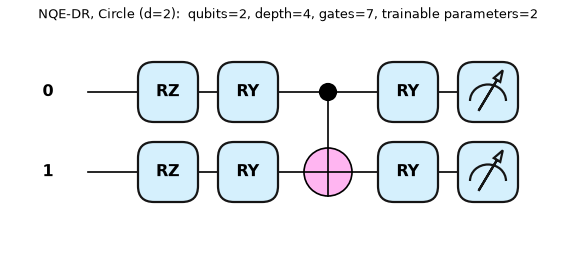

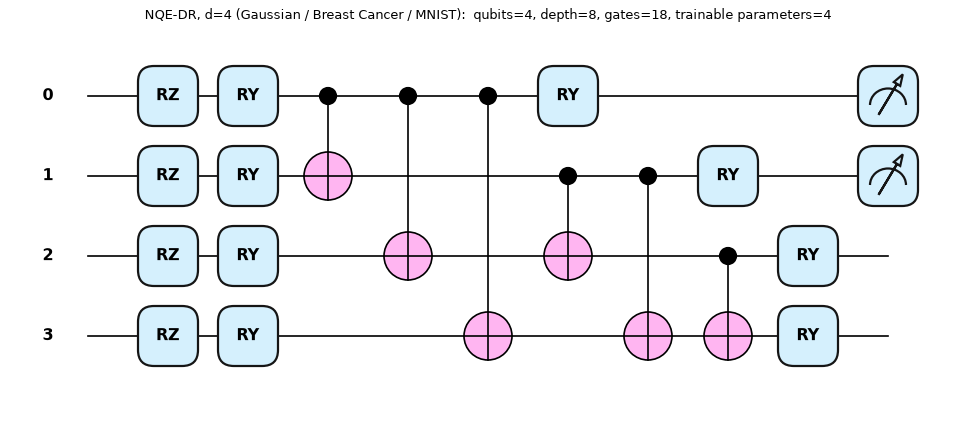

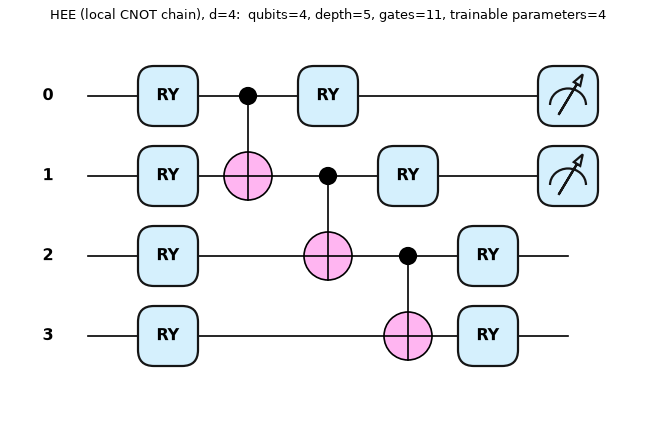

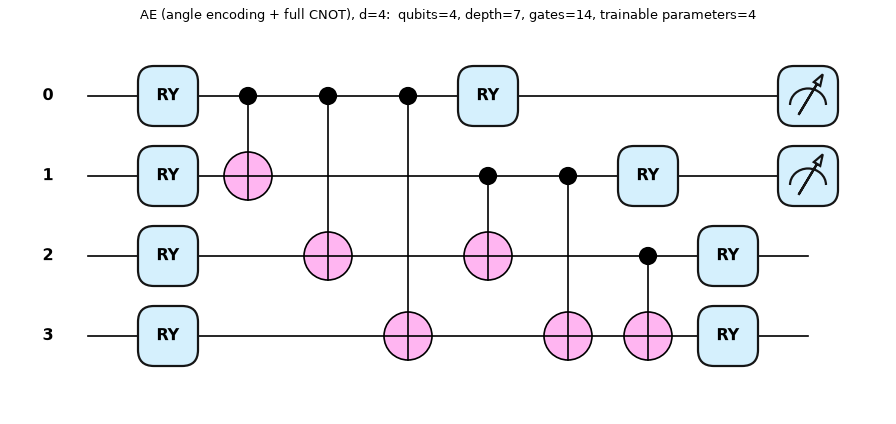

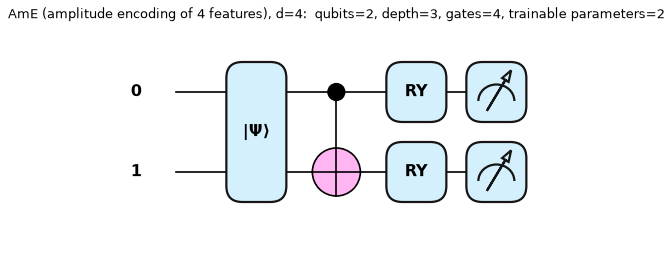

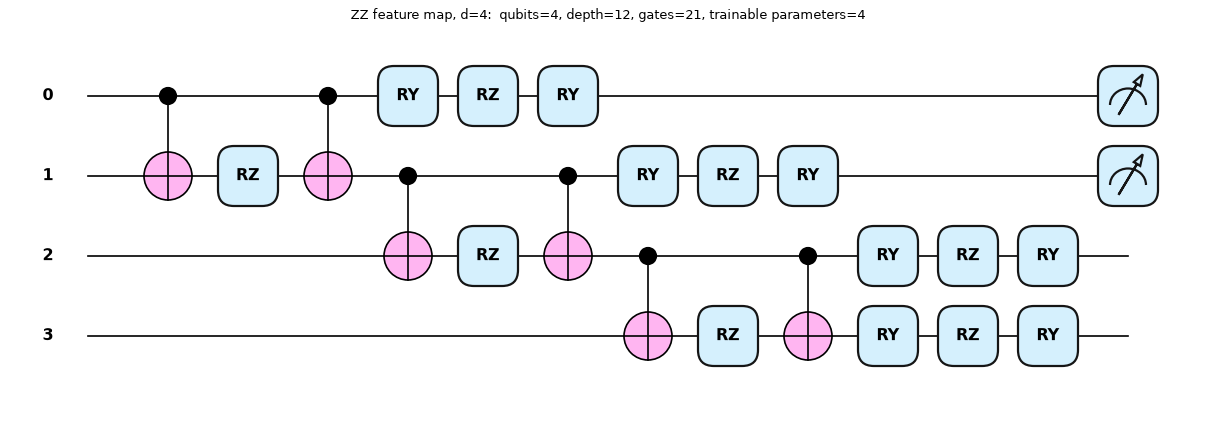

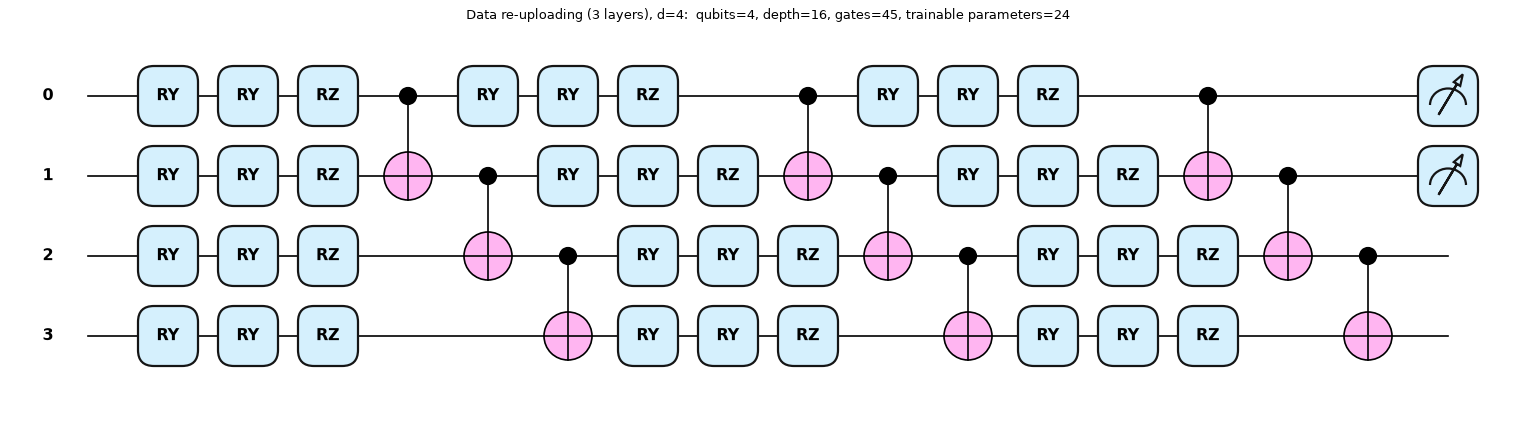

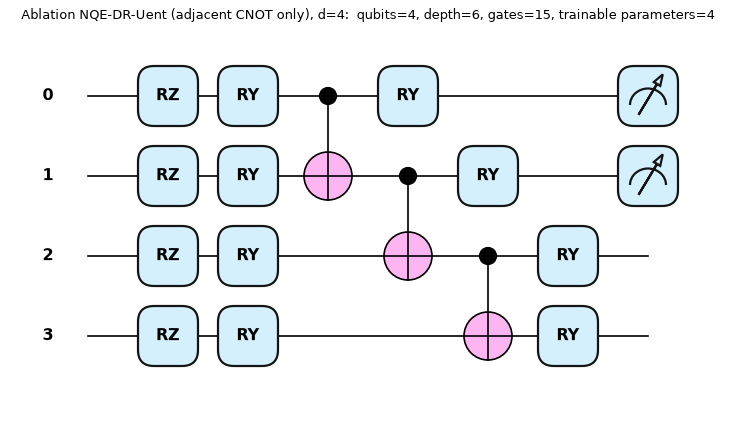

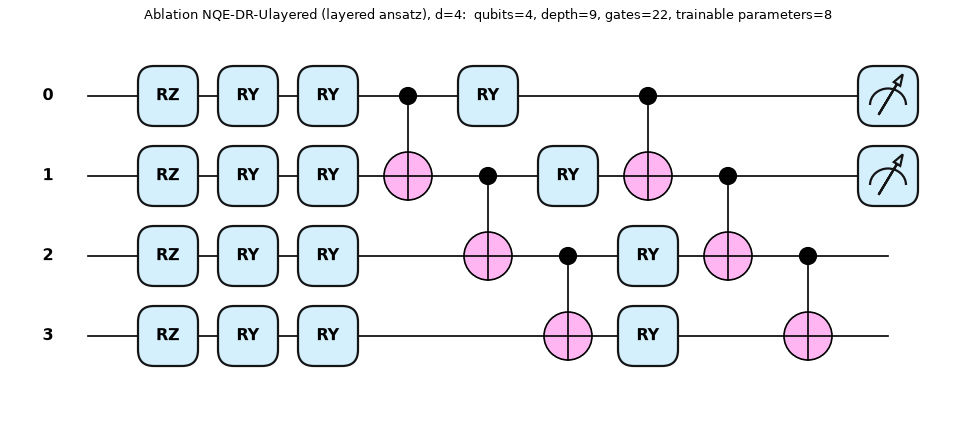

,model,qubits,depth,gates,trainable_params
0,"NQE-DR, Circle (d=2)",2,4,7,2
1,"NQE-DR, d=4 (Gaussian / Breast Cancer / MNIST)",4,8,18,4
2,"HEE (local CNOT chain), d=4",4,5,11,4
3,"AE (angle encoding + full CNOT), d=4",4,7,14,4
4,"AmE (amplitude encoding of 4 features), d=4",2,3,4,2
5,"ZZ feature map, d=4",4,12,21,4
6,"Data re-uploading (3 layers), d=4",4,16,45,24
7,"Ablation NQE-DR-Uent (adjacent CNOT only), d=4",4,6,15,4
8,"Ablation NQE-DR-Ulayered (layered ansatz), d=4",4,9,22,8


In [12]:
def describe(enc, d, layers=1, title=None):
    m = Model(enc, d, layers=layers, seed=0)
    x = torch.rand(d, generator=torch.Generator().manual_seed(1))
    fig, ax = qml.draw_mpl(m.qnode, decimals=None, style="pennylane")(x, m.phi)
    sp = qml.specs(m.qnode)(x, m.phi)
    res = sp.resources if hasattr(sp, "resources") else sp["resources"]
    depth = res.depth if hasattr(res, "depth") else res["depth"]
    ngates = res.num_gates if hasattr(res, "num_gates") else res["num_gates"]
    fig.suptitle(f"{title or enc}:  qubits={m.n}, depth={depth}, gates={ngates}, trainable parameters={m.n_params()}", y=1.02)
    plt.show()
    return dict(model=title or enc, qubits=m.n, depth=depth, gates=ngates, trainable_params=m.n_params())

d4 = DS["gaussian"]["d"]
ARCH = [("NQE-DR", DS["circle"]["d"], 1, "NQE-DR, Circle (d=2)"),
        ("NQE-DR", d4, 1, "NQE-DR, d=4 (Gaussian / Breast Cancer / MNIST)"),
        ("HEE", d4, 1, "HEE (local CNOT chain), d=4"),
        ("AE", d4, 1, "AE (angle encoding + full CNOT), d=4"),
        ("AmE", d4, 1, "AmE (amplitude encoding of 4 features), d=4"),
        ("ZZF", d4, 1, "ZZ feature map, d=4"),
        ("DRU", d4, 1, "Data re-uploading (3 layers), d=4"),
        # the ablations are run on the Circle (2 qubits, where Uent equals the full network); drawn on 4 qubits, where the entanglers differ
        ("NQE-DR-Uent", d4, 1, "Ablation NQE-DR-Uent (adjacent CNOT only), d=4"),
        ("NQE-DR-Ulayered", d4, 1, "Ablation NQE-DR-Ulayered (layered ansatz), d=4")]
rows = [describe(*a) for a in ARCH]
pd.DataFrame(rows)

In [13]:
# Equivalence: the PyTorch simulator used for training returns the same <Z0 X1> and the same input-gradients as the drawn PennyLane QNode.
checks = []
for enc, d, L in [(a[0], a[1], a[2]) for a in ARCH] + [("AE-pi", 4, 1), ("NQE-DR", 2, 3), ("NQE-DR-T", 4, 1), ("NQE-DR-deep", 5, 3)]:
    m = Model(enc, d, layers=L, seed=3)
    x = torch.rand(6, d, generator=torch.Generator().manual_seed(7))
    with torch.no_grad():
        fa, fb = m.f(x, "torch"), m.f(x, "pennylane")
    _, ga = input_grad(m, x, engine="torch"); _, gb = input_grad(m, x, engine="pennylane")
    err = max((fa - fb).abs().max().item(), (ga - gb).abs().max().item())
    assert err < 1e-9, (enc, d, L, err)
    checks.append(dict(model=enc, d=d, blocks=m.blocks, max_abs_diff=err))
print("torch simulator == PennyLane QNode (outputs and input gradients) for all architectures")
pd.DataFrame(checks)

torch simulator == PennyLane QNode (outputs and input gradients) for all architectures


,model,d,blocks,max_abs_diff
0,NQE-DR,2,1,2.220446e-16
1,NQE-DR,4,1,3.330669e-16
2,HEE,4,1,2.220446e-16
3,AE,4,1,3.330669e-16
4,AmE,4,1,2.220446e-16
5,ZZF,4,1,3.538189e-16
6,DRU,4,3,3.330669e-16
7,NQE-DR-Uent,4,1,2.220446e-16
8,NQE-DR-Ulayered,4,1,2.220446e-16
9,AE-pi,4,1,4.440892e-16


## 4. Classical baselines on identical inputs

SVC (RBF kernel, `C = 1`) and a random forest on exactly the 2 or 4 `[0, 1]` inputs the quantum models receive, and on all raw features (standardised) for reference. A small neural network (two tanh layers of width 16, binary cross-entropy, Adam) is trained on the same inputs and attacked with the same noise and FGSM protocol, to show how a classical model compares in robustness.

In [14]:
import torch.nn as nn

def train_mlp(xfit, yfit, seed, epochs=300):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(xfit.shape[1], 16), nn.Tanh(), nn.Linear(16, 16), nn.Tanh(), nn.Linear(16, 1))
    opt = torch.optim.Adam(net.parameters(), lr=0.03)
    for _ in range(epochs):
        opt.zero_grad(); nn.functional.binary_cross_entropy_with_logits(net(xfit).squeeze(1), yfit).backward(); opt.step()
    return net

def mlp_acc(net, x, y):
    with torch.no_grad():
        return ((net(x).squeeze(1) > 0).long() == y.long()).double().mean().item()

def mlp_eval(net, x, y, eps_list, seed):
    gen = torch.Generator().manual_seed(SEED + seed)
    noise = [float(np.mean([mlp_acc(net, noise_attack(x, e, gen), y) for _ in range(N_NOISE_DRAWS)])) for e in eps_list]
    fg = []
    for e in eps_list:
        xg = x.clone().requires_grad_(True)
        nn.functional.binary_cross_entropy_with_logits(net(xg).squeeze(1), y, reduction="sum").backward()
        fg.append(mlp_acc(net, (x + e * xg.grad.sign()).clamp(0, 1).detach(), y))
    return noise, fg

CLASSICAL = {}
for name, d in DS.items():
    xf, yf, xt, yt = d["xfit"].numpy(), d["yfit"].numpy().astype(int), d["xte"].numpy(), d["yte"].numpy().astype(int)
    res = {}
    res["SVC-rbf (same inputs)"] = SVC(kernel="rbf", C=1.0, random_state=SEED).fit(xf, yf).score(xt, yt)
    res["RandomForest (same inputs)"] = RandomForestClassifier(200, random_state=SEED, n_jobs=1).fit(xf, yf).score(xt, yt)
    sc = StandardScaler().fit(d["raw"]["fit"])
    Rf, Rt = sc.transform(d["raw"]["fit"]), sc.transform(d["raw"]["te"])
    res["SVC-rbf (all raw features)"] = SVC(kernel="rbf", C=1.0, random_state=SEED).fit(Rf, yf).score(Rt, yt)
    res["RandomForest (all raw features)"] = RandomForestClassifier(200, random_state=SEED, n_jobs=1).fit(Rf, yf).score(Rt, yt)
    mlp_runs = []
    for s in range(N_SEEDS):
        net = train_mlp(d["xfit"], d["yfit"], SEED + s)
        nz, fg = mlp_eval(net, d["xte"], d["yte"], EPS_LEVELS, s)
        mlp_runs.append(dict(clean=mlp_acc(net, d["xte"], d["yte"]), noise=nz, fgsm=fg))
    res["MLP (same inputs)"] = float(np.mean([r["clean"] for r in mlp_runs]))
    CLASSICAL[name] = dict(clean=res, mlp_noise=np.mean([r["noise"] for r in mlp_runs], 0), mlp_fgsm=np.mean([r["fgsm"] for r in mlp_runs], 0))
print(pd.DataFrame({k: v["clean"] for k, v in CLASSICAL.items()}).round(3).to_string())

                                 circle  gaussian  breast_cancer  mnist01
SVC-rbf (same inputs)             0.980       1.0          0.959    0.999
RandomForest (same inputs)        0.950       1.0          0.947    0.998
SVC-rbf (all raw features)        0.980       1.0          0.994    0.996
RandomForest (all raw features)   0.950       1.0          0.953    1.000
MLP (same inputs)                 0.987       1.0          0.978    0.998


## 4b. An unspecified detail that matters: the readout scale

The model output `f(x) = <Z_0 X_1>` lies in `[-1, 1]`, but after the sigmoid and squaring the encoder only moves the angles by a few tenths of a radian, so `f` varies very little across the data. A cross-entropy on the authors' linear link `p = (f + 1) / 2` is then minimised by predicting the class prior for every sample (the model sits at the majority-class accuracy), even though a random search over the parameters finds settings that classify the same data almost perfectly. The paper does not state a readout scale. We therefore compare `p = sigmoid(s f)` for `s in {None (linear link), 3, 10, 30}` on **validation** accuracy, pooled over all four encodings and three data sets (so the choice does not favour NQE-DR), and fix `LOGIT_SCALE = 10` in the configuration (rule: among the scales within 0.01 pooled validation accuracy of the best one, the smallest, which gives the smoothest loss). The table is evidence for that choice; the test sets are not touched here.

In [15]:
def scale_study(scales, seeds, epochs):
    global LOGIT_SCALE
    keep, rows = LOGIT_SCALE, []
    for s in scales:
        LOGIT_SCALE = s
        for dname in ["circle", "gaussian", "breast_cancer"]:
            d = DS[dname]
            for enc in ["NQE-DR", "HEE", "AE", "AmE"]:
                vals = []
                for sd in range(seeds):
                    m = Model(enc, d["d"], seed=SEED + sd)
                    train(m, d["xfit"], d["yfit"], d["xva"], d["yva"], LAM1, LAM2, epochs, lr=LR, seed=SEED + sd)
                    vals.append(accuracy(m, d["xva"], d["yva"]))
                rows.append(dict(readout="linear (f+1)/2" if s is None else f"sigmoid({s:g} f)", dataset=dname, encoding=enc, val_acc=float(np.mean(vals))))
    LOGIT_SCALE = keep
    return pd.DataFrame(rows)

t0 = time.time()
LS = scale_study(SCALE_GRID, LS_SEEDS, LS_EPOCHS)
order = list(dict.fromkeys(LS.readout))
tab = LS.pivot_table(index="readout", columns="dataset", values="val_acc", aggfunc="mean").loc[order]
tab["pooled"] = tab.mean(axis=1)
print(f"readout-scale study: {time.time() - t0:.0f} s  ({LS_SEEDS} seed(s), {LS_EPOCHS} epochs)  - mean VALIDATION accuracy over the 4 encodings")
print(tab.round(3).to_string())
near_best = [r for r in tab.index if tab.pooled[r] >= tab.pooled.max() - 0.01 and r.startswith("sigmoid")]
print("\nbest pooled readout in this study:", tab.pooled.idxmax(), "| within 0.01 of the best:", near_best, "| configured LOGIT_SCALE =", LOGIT_SCALE,
      "(rule: among the scales within 0.01 pooled validation accuracy of the best, take the smallest, because it gives the smoothest loss)")
print("majority-class rate of the validation sets:", {k: round(max(float(DS[k]['yva'].mean()), 1 - float(DS[k]['yva'].mean())), 3) for k in ['circle', 'gaussian', 'breast_cancer']})

readout-scale study: 694 s  (1 seed(s), 100 epochs)  - mean VALIDATION accuracy over the 4 encodings
dataset         breast_cancer  circle  gaussian  pooled
readout                                                
linear (f+1)/2          0.675   0.559     0.686   0.640
sigmoid(3 f)            0.691   0.561     0.698   0.650
sigmoid(10 f)           0.850   0.566     0.945   0.787
sigmoid(30 f)           0.834   0.566     0.943   0.781

best pooled readout in this study: sigmoid(10 f) | within 0.01 of the best: ['sigmoid(10 f)', 'sigmoid(30 f)'] | configured LOGIT_SCALE = 10.0 (rule: among the scales within 0.01 pooled validation accuracy of the best, take the smallest, because it gives the smoothest loss)
majority-class rate of the validation sets: {'circle': 0.521, 'gaussian': 0.65, 'breast_cancer': 0.662}


## 5. Training the four encodings (Table 1, Figures 4 to 6)

NQE-DR, HEE, AE and AmE are trained on Circle, Gaussian mixture and Breast Cancer with Adam (`lr = 0.1`), `lambda1 = 0.01`, `lambda2 = 0.2`, and the same initialisation rule (`phi ~ U(0, pi)`), for `EPOCHS` full-batch epochs. For each trained model we immediately evaluate clean accuracy, the noise and FGSM attacks at all strengths of Table 2, and the Lipschitz estimate; results are averaged over `N_SEEDS` seeds.

In [16]:
# ---- numbers transcribed from the paper (New J. Phys. 28 (2026) 014511) ----------------------------
ENC4 = ["NQE-DR", "HEE", "AE", "AmE"]
PAPER_T1 = {   # Table 1: clean accuracy
    "circle":        dict(zip(ENC4, [0.978, 0.945, 0.930, 0.880])),
    "gaussian":      dict(zip(ENC4, [0.985, 0.970, 0.960, 0.930])),
    "breast_cancer": dict(zip(ENC4, [0.958, 0.945, 0.948, 0.922])),
}
EPS10 = [round(0.1 * k, 1) for k in range(1, 11)]
# Table 2: rows eps = 0.1 ... 1.0 ; columns NQE-DR, HEE, AE, AmE ; first block = random noise, second = FGSM
_T2 = {
 "circle": ([[.938,.875,.890,.855],[.860,.825,.841,.831],[.821,.743,.770,.761],[.783,.731,.711,.660],[.764,.700,.690,.651],
             [.681,.669,.599,.612],[.652,.630,.574,.558],[.630,.589,.564,.529],[.591,.562,.528,.481],[.573,.505,.501,.454]],
            [[.945,.932,.902,.875],[.875,.900,.874,.843],[.842,.840,.843,.795],[.795,.795,.794,.754],[.754,.752,.766,.711],
             [.694,.683,.690,.656],[.665,.641,.653,.601],[.632,.594,.583,.563],[.587,.564,.545,.512],[.535,.511,.492,.462]]),
 "gaussian": ([[.931,.928,.919,.911],[.895,.877,.874,.854],[.845,.842,.845,.821],[.809,.785,.775,.743],[.763,.754,.728,.682],
               [.732,.712,.705,.621],[.658,.632,.653,.572],[.619,.592,.585,.510],[.545,.521,.512,.456],[.508,.482,.477,.398]],
              [[.920,.935,.920,.910],[.890,.885,.821,.832],[.851,.843,.710,.721],[.793,.711,.658,.620],[.754,.670,.610,.601],
               [.711,.659,.531,.572],[.692,.610,.498,.548],[.650,.582,.464,.439],[.621,.531,.431,.381],[.609,.490,.375,.334]]),
 "breast_cancer": ([[.931,.918,.921,.895],[.894,.863,.875,.832],[.863,.829,.834,.789],[.821,.787,.792,.710],[.785,.729,.719,.652],
                    [.731,.685,.645,.602],[.686,.649,.603,.565],[.653,.601,.574,.531],[.618,.561,.532,.478],[.553,.502,.473,.403]],
                   [[.929,.915,.903,.882],[.890,.855,.849,.838],[.858,.819,.807,.782],[.797,.759,.745,.727],[.743,.719,.686,.665],
                    [.698,.672,.654,.605],[.659,.642,.630,.558],[.626,.600,.591,.505],[.592,.549,.532,.463],[.528,.495,.435,.393]]),
}
PAPER_T2 = {d: {"noise": {e: dict(zip(ENC4, row)) for e, row in zip(EPS10, v[0])},
                "fgsm":  {e: dict(zip(ENC4, row)) for e, row in zip(EPS10, v[1])}} for d, v in _T2.items()}
EPS4 = [0.1, 0.3, 0.5, 0.7]
def _row9(v):   # clean | noise x4 | fgsm x4
    return {"clean": v[0], "noise": dict(zip(EPS4, v[1:5])), "fgsm": dict(zip(EPS4, v[5:9]))}
PAPER_T3 = {   # Table 3: MNIST 0 vs 1
    "NQE-DR": _row9([.969,.935,.818,.749,.638,.939,.841,.747,.672]),
    "DRU":    _row9([.969,.922,.801,.736,.624,.929,.823,.739,.643]),
    "ZZF":    _row9([.961,.906,.778,.721,.607,.918,.809,.722,.628]),
    "HEE":    _row9([.952,.887,.740,.695,.627,.907,.792,.711,.649]),
    "AE":     _row9([.945,.871,.765,.686,.571,.898,.762,.685,.639]),
    "AmE":    _row9([.929,.851,.757,.647,.553,.872,.750,.707,.597]),
}
PAPER_T4 = {   # Table 4: ablation on Circle
    "NQE-DR":          _row9([.978,.938,.821,.764,.652,.945,.842,.754,.665]),
    "NQE-DR-T":        _row9([.945,.890,.753,.680,.610,.921,.805,.650,.602]),
    "NQE-DR-Uent":     _row9([.960,.911,.790,.734,.633,.930,.835,.725,.643]),
    "NQE-DR-Ulayered": _row9([.968,.925,.805,.745,.640,.938,.838,.740,.655]),
    "NQE-DR-R":        _row9([.963,.895,.761,.710,.625,.919,.814,.680,.614]),
}
PAPER_LIPSCHITZ_NQEDR = 9.5     # Fig. 7 / text of Sec. 4.2 (lowest of the four encodings)

In [17]:
def evaluate(model, d, eps_list, seed):
    gen = torch.Generator().manual_seed(SEED + 1000 * seed)
    xte, yte = d["xte"], d["yte"]
    out = {"clean": accuracy(model, xte, yte)}
    out["noise"] = [float(np.mean([accuracy(model, noise_attack(xte, e, gen), yte) for _ in range(N_NOISE_DRAWS)])) for e in eps_list]
    out["fgsm"] = [accuracy(model, fgsm_attack(model, xte, yte, e), yte) for e in eps_list]
    out["lip"] = lipschitz_estimate(model, d["xva"], 50)
    return out

def run_one(dname, enc, seed, layers=LAYERS, lam1=LAM1, lam2=LAM2, epochs=EPOCHS, batch=None, eps_list=EPS_LEVELS):
    d = DS[dname]
    m = Model(enc, d["d"], layers=layers, seed=SEED + seed)
    t0 = time.time()
    hist, best_ep = train(m, d["xfit"], d["yfit"], d["xva"], d["yva"], lam1, lam2, epochs, lr=LR, batch=batch, seed=SEED + seed)
    res = evaluate(m, d, eps_list, seed)
    res.update(hist=hist, best_epoch=best_ep, seconds=time.time() - t0, params=m.phi.detach().numpy().ravel())
    return res

MAIN = {}
t_start = time.time()
for dname in ["circle", "gaussian", "breast_cancer"]:
    for enc in ENC4:
        MAIN[(dname, enc)] = [run_one(dname, enc, s) for s in range(N_SEEDS)]
        r = MAIN[(dname, enc)]
        print(f"{dname:14s} {enc:7s} clean {np.mean([x['clean'] for x in r]):.3f} +- {np.std([x['clean'] for x in r]):.3f}   "
              f"({np.mean([x['seconds'] for x in r]):.0f} s/run, best epoch {[x['best_epoch'] for x in r]})", flush=True)
print(f"main experiment: {(time.time() - t_start) / 60:.1f} min")

circle         NQE-DR  clean 0.611 +- 0.010   (22 s/run, best epoch [10, 53, 15])


circle         HEE     clean 0.611 +- 0.050   (15 s/run, best epoch [9, 37, 63])


circle         AE      clean 0.611 +- 0.050   (12 s/run, best epoch [9, 37, 63])


circle         AmE     clean 0.633 +- 0.000   (7 s/run, best epoch [43, 3, 23])


gaussian       NQE-DR  clean 0.917 +- 0.109   (55 s/run, best epoch [9, 37, 104])


...

breast_cancer  NQE-DR  clean 0.858 +- 0.072   (41 s/run, best epoch [37, 37, 23])


breast_cancer  HEE     clean 0.822 +- 0.047   (24 s/run, best epoch [102, 26, 62])


breast_cancer  AE      clean 0.923 +- 0.010   (23 s/run, best epoch [26, 22, 27])


breast_cancer  AmE     clean 0.968 +- 0.003   (7 s/run, best epoch [14, 60, 49])


main experiment: 13.9 min


In [18]:
# Table 1: clean accuracy, notebook versus paper
rows = []
for dname in ["circle", "gaussian", "breast_cancer"]:
    for enc in ENC4:
        v = [x["clean"] for x in MAIN[(dname, enc)]]
        rows.append(dict(dataset=dname, encoding=enc, notebook_mean=np.mean(v), notebook_std=np.std(v), paper=PAPER_T1[dname][enc],
                         gap=np.mean(v) - PAPER_T1[dname][enc]))
T1 = pd.DataFrame(rows)
print(T1.pivot(index="encoding", columns="dataset", values="notebook_mean").loc[ENC4].round(3).to_string())
print("\npaper:")
print(pd.DataFrame(PAPER_T1).loc[ENC4].to_string())
T1.round(3)

dataset   breast_cancer  circle  gaussian
encoding                                 
NQE-DR            0.858   0.611     0.917
HEE               0.822   0.611     0.872
AE                0.923   0.611     0.988
AmE               0.968   0.633     0.813

paper:
        circle  gaussian  breast_cancer
NQE-DR   0.978     0.985          0.958
HEE      0.945     0.970          0.945
AE       0.930     0.960          0.948
AmE      0.880     0.930          0.922


,dataset,encoding,notebook_mean,notebook_std,paper,gap
0,circle,NQE-DR,0.611,0.010,0.978,-0.367
1,circle,HEE,0.611,0.050,0.945,-0.334
2,circle,AE,0.611,0.050,0.930,-0.319
3,circle,AmE,0.633,0.000,0.880,-0.247
4,gaussian,NQE-DR,0.917,0.109,0.985,-0.068
5,gaussian,HEE,0.872,0.058,0.970,-0.098
6,gaussian,AE,0.988,0.002,0.960,0.028
7,gaussian,AmE,0.813,0.010,0.930,-0.117
8,breast_cancer,NQE-DR,0.858,0.072,0.958,-0.100
9,breast_cancer,HEE,0.822,0.047,0.945,-0.123


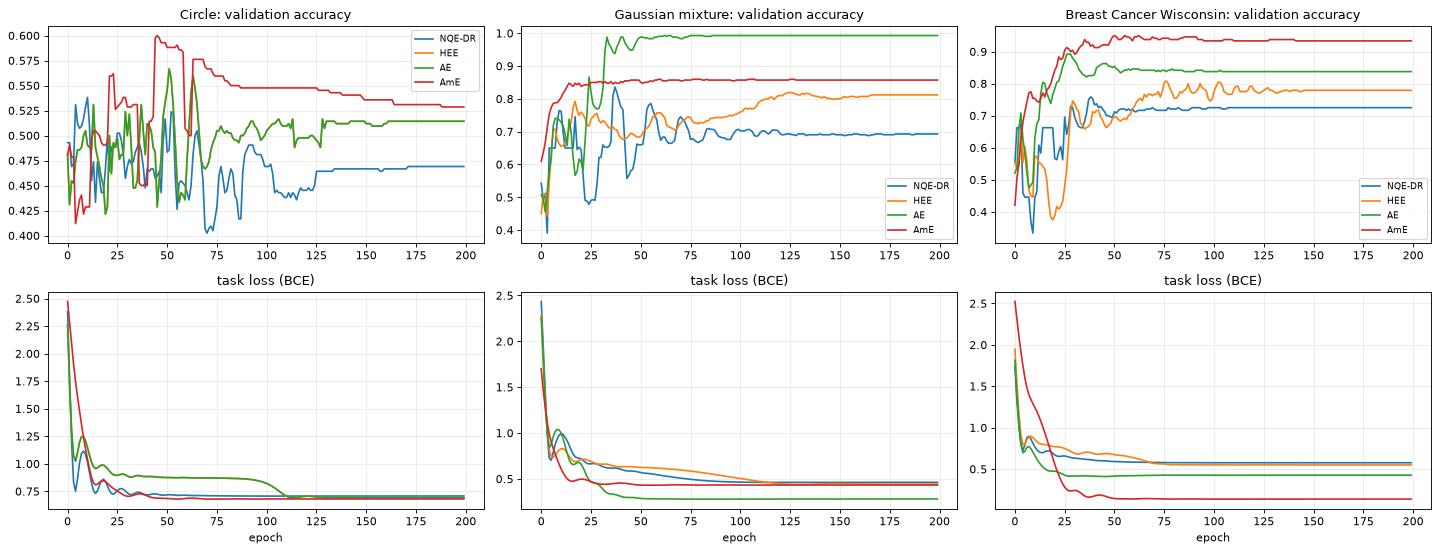

In [19]:
# Figures 4-6 analogue: validation accuracy and task loss during training (mean over seeds)
fig, ax = plt.subplots(2, 3, figsize=(18, 7))
for j, dname in enumerate(["circle", "gaussian", "breast_cancer"]):
    for enc in ENC4:
        H = [x["hist"] for x in MAIN[(dname, enc)]]
        ax[0, j].plot(np.mean([h["val_acc"] for h in H], 0), label=enc)
        ax[1, j].plot(np.mean([h["task"] for h in H], 0), label=enc)
    ax[0, j].set_title(f"{RAW[dname]['title']}: validation accuracy"); ax[1, j].set_title("task loss (BCE)")
    ax[1, j].set_xlabel("epoch"); ax[0, j].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Robustness under noise and FGSM (Table 2) and the Lipschitz estimate (Figure 7)

Every trained model is attacked on the test set with random noise of strength `eps` and with white-box FGSM of strength `delta` (0.1 to 1.0), always clipped back to `[0, 1]`. Solid lines are this notebook, dashed lines the paper's Table 2.

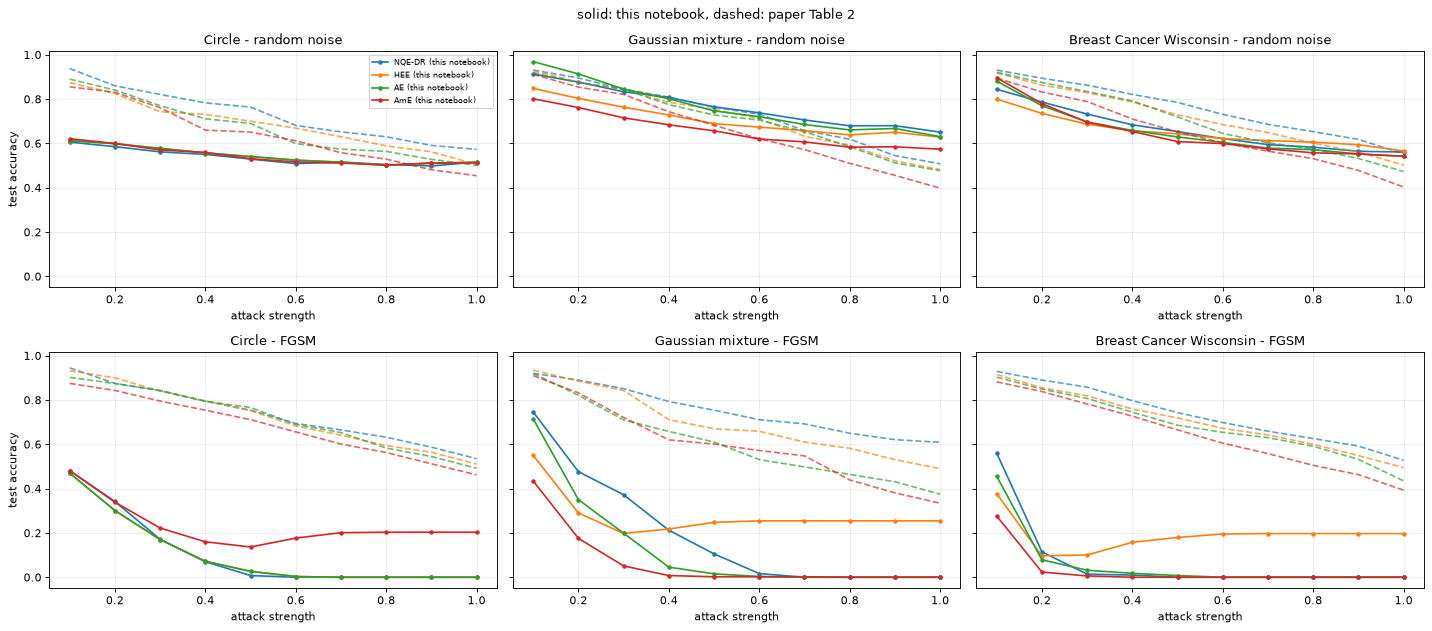

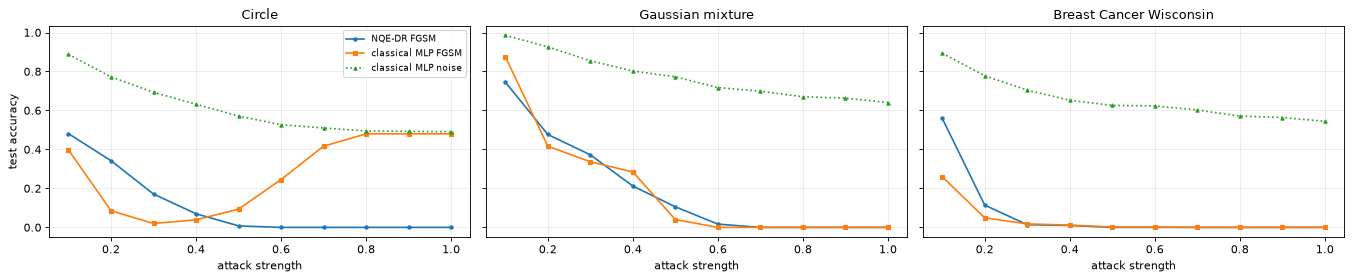

FGSM accuracy at strength 0.1 / 0.5 / 1.0 (white-box, this notebook):
  circle         NQE-DR [0.481 0.008 0.   ]  classical MLP [0.398 0.093 0.48 ]  |  paper NQE-DR [0.945, 0.754, 0.535]
  gaussian       NQE-DR [0.746 0.106 0.   ]  classical MLP [0.876 0.04  0.   ]  |  paper NQE-DR [0.92, 0.754, 0.609]
  breast_cancer  NQE-DR [0.56 0.   0.  ]  classical MLP [0.26  0.002 0.   ]  |  paper NQE-DR [0.929, 0.743, 0.528]


In [20]:
def curve(dname, enc, kind):
    return np.mean([x[kind] for x in MAIN[(dname, enc)]], 0)

fig, ax = plt.subplots(2, 3, figsize=(18, 8), sharey=True)
colors = dict(zip(ENC4, plt.cm.tab10([0, 1, 2, 3])))
for i, kind in enumerate(["noise", "fgsm"]):
    for j, dname in enumerate(["circle", "gaussian", "breast_cancer"]):
        for enc in ENC4:
            ax[i, j].plot(EPS_LEVELS, curve(dname, enc, kind), color=colors[enc], marker="o", ms=3, label=f"{enc} (this notebook)")
            ax[i, j].plot(EPS_LEVELS, [PAPER_T2[dname][kind][e][enc] for e in EPS_LEVELS], color=colors[enc], ls="--", alpha=0.7)
        ax[i, j].set_title(f"{RAW[dname]['title']} - {'random noise' if kind == 'noise' else 'FGSM'}"); ax[i, j].set_xlabel("attack strength")
ax[0, 0].set_ylabel("test accuracy"); ax[1, 0].set_ylabel("test accuracy"); ax[0, 0].legend(fontsize=7)
plt.suptitle("solid: this notebook, dashed: paper Table 2"); plt.tight_layout(); plt.show()

# classical neural network under the same attacks (not in the paper)
fig, ax = plt.subplots(1, 3, figsize=(17, 3.6), sharey=True)
for j, dname in enumerate(["circle", "gaussian", "breast_cancer"]):
    ax[j].plot(EPS_LEVELS, curve(dname, "NQE-DR", "fgsm"), label="NQE-DR FGSM", marker="o", ms=3)
    ax[j].plot(EPS_LEVELS, CLASSICAL[dname]["mlp_fgsm"], label="classical MLP FGSM", marker="s", ms=3)
    ax[j].plot(EPS_LEVELS, CLASSICAL[dname]["mlp_noise"], label="classical MLP noise", marker="^", ms=3, ls=":")
    ax[j].set_title(RAW[dname]["title"]); ax[j].set_xlabel("attack strength")
ax[0].set_ylabel("test accuracy"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
sel = [EPS_LEVELS.index(e) for e in (0.1, 0.5, 1.0)]
print("FGSM accuracy at strength 0.1 / 0.5 / 1.0 (white-box, this notebook):")
for dn in ["circle", "gaussian", "breast_cancer"]:
    print(f"  {dn:14s} NQE-DR {np.round(curve(dn, 'NQE-DR', 'fgsm')[sel], 3)}  classical MLP {np.round(CLASSICAL[dn]['mlp_fgsm'][sel], 3)}  |  paper NQE-DR {[PAPER_T2[dn]['fgsm'][e]['NQE-DR'] for e in (0.1, 0.5, 1.0)]}")

In [21]:
# Table 2 quantitative comparison
rows = []
for dname in ["circle", "gaussian", "breast_cancer"]:
    for kind in ["noise", "fgsm"]:
        for enc in ENC4:
            ours = curve(dname, enc, kind); paper = np.array([PAPER_T2[dname][kind][e][enc] for e in EPS_LEVELS])
            rows.append(dict(dataset=dname, attack=kind, encoding=enc, mean_abs_gap=np.abs(ours - paper).mean(),
                             ours_at_1_0=ours[-1], paper_at_1_0=paper[-1]))
T2 = pd.DataFrame(rows)
print(T2.pivot_table(index=["dataset", "attack"], columns="encoding", values="mean_abs_gap")[ENC4].round(3).to_string())

# "NQE-DR has the highest accuracy in the cell" (ties count as best): paper versus notebook
best_p, best_n, n_cells = 0, 0, 0
for dname in ["circle", "gaussian", "breast_cancer"]:
    for kind in ["noise", "fgsm"]:
        ours = {e: curve(dname, e, kind) for e in ENC4}
        for k, eps in enumerate(EPS_LEVELS):
            n_cells += 1
            best_p += PAPER_T2[dname][kind][eps]["NQE-DR"] >= max(PAPER_T2[dname][kind][eps][e] for e in ENC4[1:])
            best_n += ours["NQE-DR"][k] >= max(ours[e][k] for e in ENC4[1:]) - 1e-12
print(f"\nNQE-DR is best (vs HEE, AE, AmE) in {best_p}/{n_cells} cells of the paper's Table 2 and in {best_n}/{n_cells} cells here")

encoding              NQE-DR    HEE     AE    AmE
dataset       attack                             
breast_cancer fgsm     0.662  0.513  0.624  0.611
              noise    0.093  0.080  0.066  0.050
circle        fgsm     0.625  0.617  0.610  0.445
              noise    0.192  0.139  0.124  0.113
gaussian      fgsm     0.556  0.414  0.469  0.528
              noise    0.044  0.074  0.057  0.081

NQE-DR is best (vs HEE, AE, AmE) in 56/60 cells of the paper's Table 2 and in 22/60 cells here


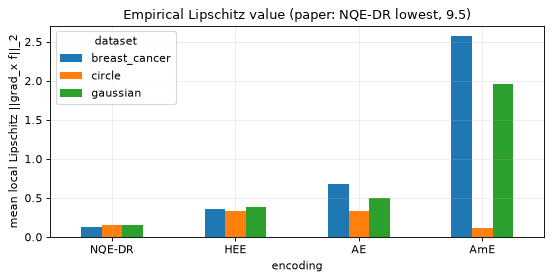

dataset   breast_cancer  circle  gaussian
encoding                                 
NQE-DR            0.128   0.159     0.154
HEE               0.361   0.338     0.385
AE                0.674   0.338     0.506
AmE               2.577   0.109     1.961

lowest Lipschitz value per data set: {'breast_cancer': 'NQE-DR', 'circle': 'AmE', 'gaussian': 'NQE-DR'} | highest: {'breast_cancer': 'AmE', 'circle': 'HEE', 'gaussian': 'AmE'}


In [22]:
# Figure 7: empirical Lipschitz value (mean ||grad_x f|| over 50 validation samples), per encoding and data set
rows = [dict(dataset=dn, encoding=e, lipschitz=np.mean([x["lip"] for x in MAIN[(dn, e)]])) for dn in ["circle", "gaussian", "breast_cancer"] for e in ENC4]
LIP = pd.DataFrame(rows)
piv = LIP.pivot(index="encoding", columns="dataset", values="lipschitz").loc[ENC4]
fig, ax = plt.subplots(figsize=(7, 3.6)); piv.plot.bar(ax=ax); ax.set_ylabel("mean local Lipschitz ||grad_x f||_2"); ax.set_title("Empirical Lipschitz value (paper: NQE-DR lowest, 9.5)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print(piv.round(3).to_string())
print("\nlowest Lipschitz value per data set:", piv.idxmin().to_dict(), "| highest:", piv.idxmax().to_dict())

## 7. Scalability of the Lipschitz value (Figure 8)

For `n` qubits and `d` repetitions of [full CNOT network, trainable RY layer] after a single NQE-DR encoding, we draw random inputs in `[0, 1]^n` and random parameters in `(0, pi)`, and average `||grad_x f||_2`. The paper reports a substantial value for `n <= 12`, `d <= 8` with a slow decay as either grows (the effect of barren plateaus on the input-gradient regulariser).

scaling study: 61 s
        d=3    d=4    d=5    d=6    d=8
n=4   0.128  0.116  0.169  0.128  0.140
n=6   0.107  0.080  0.088  0.085  0.070
n=8   0.112  0.059  0.054  0.051  0.045
n=10  0.083  0.035  0.044  0.041  0.034
n=12  0.053  0.028  0.028  0.015  0.019


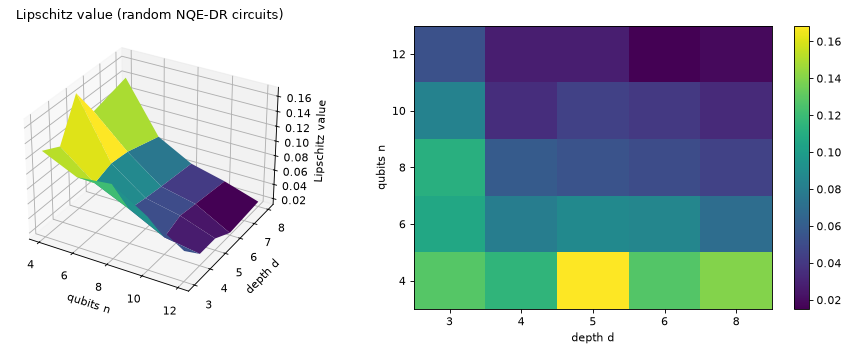

Spearman correlation of the Lipschitz value with n: -0.90, with d: -0.28; smallest value 0.015


In [23]:
def lipschitz_scaling(n, depth, samples, seed=SEED):
    vals = []
    for s in range(samples):
        g = torch.Generator().manual_seed(seed + 97 * s)
        x = torch.rand(16, n, generator=g)
        m = Model("NQE-DR-deep", n, layers=depth, seed=seed + s)
        vals.append(lipschitz_estimate(m, x, 16))
    return float(np.mean(vals)), float(np.std(vals))

t0 = time.time()
SCALE = pd.DataFrame([[lipschitz_scaling(n, dd, SCALE_SAMPLES)[0] for dd in SCALE_DS] for n in SCALE_NS], index=[f"n={n}" for n in SCALE_NS], columns=[f"d={dd}" for dd in SCALE_DS])
print(f"scaling study: {time.time() - t0:.0f} s")
print(SCALE.round(3).to_string())
from mpl_toolkits.mplot3d import Axes3D   # noqa: F401
fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
NN, DD = np.meshgrid(SCALE_NS, SCALE_DS, indexing="ij")
ax.plot_surface(NN, DD, SCALE.values, cmap="viridis"); ax.set_xlabel("qubits n"); ax.set_ylabel("depth d"); ax.set_zlabel("Lipschitz value"); ax.set_title("Lipschitz value (random NQE-DR circuits)")
ax2 = fig.add_subplot(1, 2, 2); im = ax2.imshow(SCALE.values, origin="lower", aspect="auto", cmap="viridis")
ax2.set_xticks(range(len(SCALE_DS)), SCALE_DS); ax2.set_yticks(range(len(SCALE_NS)), SCALE_NS); ax2.set_xlabel("depth d"); ax2.set_ylabel("qubits n"); plt.colorbar(im, ax=ax2); ax2.grid(False)
plt.tight_layout(); plt.show()
rho_n = spearmanr(np.repeat(SCALE_NS, len(SCALE_DS)), SCALE.values.ravel())[0]
rho_d = spearmanr(np.tile(SCALE_DS, len(SCALE_NS)), SCALE.values.ravel())[0]
print(f"Spearman correlation of the Lipschitz value with n: {rho_n:+.2f}, with d: {rho_d:+.2f}; smallest value {SCALE.values.min():.3f}")

## 8. MNIST 0 versus 1 against six encodings (Table 3)

NQE-DR, data re-uploading (DRU, 3 layers), ZZ feature map (ZZF), HEE, AE and AmE on the 4 PCA features of MNIST digits 0 vs 1 (12 665 training images). Each Adam step uses a random mini-batch (`MNIST_BATCH` images, `MNIST_STEPS` steps) instead of the full batch to keep memory small. Evaluation uses all 2 115 test images.

NQE-DR  clean 0.986   (74 s/run)


DRU     clean 0.996   (166 s/run)


ZZF     clean 0.997   (67 s/run)


HEE     clean 0.845   (31 s/run)


AE      clean 0.975   (34 s/run)


AmE     clean 0.846   (7 s/run)


MNIST experiment: 12.6 min
this notebook:
        clean  noise 0.1  noise 0.3  noise 0.5  noise 0.7  FGSM 0.1  FGSM 0.3  FGSM 0.5  FGSM 0.7
NQE-DR  0.986      0.982      0.907      0.777      0.702     0.917     0.101     0.001     0.000
DRU     0.996      0.995      0.931      0.795      0.702     0.966     0.337     0.337     0.383
ZZF     0.997      0.995      0.882      0.767      0.698     0.974     0.313     0.089     0.002
HEE     0.845      0.808      0.743      0.670      0.620     0.548     0.014     0.000     0.000
AE      0.975      0.968      0.887      0.775      0.703     0.871     0.061     0.000     0.000
AmE     0.846      0.810      0.718      0.650      0.603     0.468     0.038     0.000     0.000

paper Table 3:
        clean  noise 0.1  noise 0.3  noise 0.5  noise 0.7  FGSM 0.1  FGSM 0.3  FGSM 0.5  FGSM 0.7
NQE-DR  0.969      0.935      0.818      0.749      0.638     0.939     0.841     0.747     0.672
DRU     0.969      0.922      0.801      0.736      0.624   

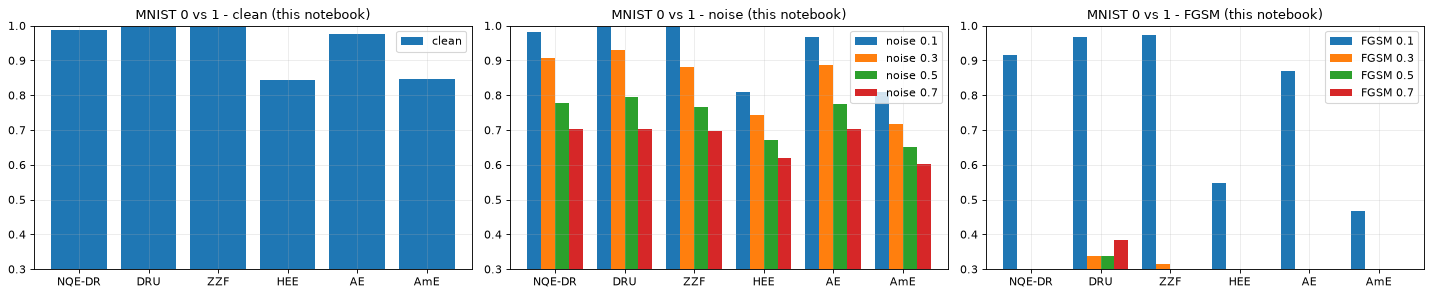


NQE-DR is best of the six in 9/9 columns of the paper's Table 3 and in 0/9 columns here


In [24]:
ENC6 = ["NQE-DR", "DRU", "ZZF", "HEE", "AE", "AmE"]
MN = {}
t0 = time.time()
for enc in ENC6:
    MN[enc] = [run_one("mnist01", enc, s, epochs=MNIST_STEPS, batch=MNIST_BATCH, eps_list=EPS_MNIST) for s in range(MNIST_SEEDS)]
    print(f"{enc:7s} clean {np.mean([x['clean'] for x in MN[enc]]):.3f}   ({np.mean([x['seconds'] for x in MN[enc]]):.0f} s/run)", flush=True)
print(f"MNIST experiment: {(time.time() - t0) / 60:.1f} min")

def row9(res_list):
    return [np.mean([x["clean"] for x in res_list])] + list(np.mean([x["noise"] for x in res_list], 0)) + list(np.mean([x["fgsm"] for x in res_list], 0))
cols = ["clean"] + [f"noise {e}" for e in EPS_MNIST] + [f"FGSM {e}" for e in EPS_MNIST]
T3_ours = pd.DataFrame({e: row9(MN[e]) for e in ENC6}, index=cols).T
T3_paper = pd.DataFrame({e: [PAPER_T3[e]["clean"]] + [PAPER_T3[e]["noise"][k] for k in EPS_MNIST] + [PAPER_T3[e]["fgsm"][k] for k in EPS_MNIST] for e in ENC6}, index=cols).T
print("this notebook:"); print(T3_ours.round(3).to_string())
print("\npaper Table 3:"); print(T3_paper.round(3).to_string())
fig, ax = plt.subplots(1, 3, figsize=(18, 3.8))
for a, sel, ttl in zip(ax, [["clean"], [c for c in cols if c.startswith("noise")], [c for c in cols if c.startswith("FGSM")]], ["clean", "noise", "FGSM"]):
    (T3_ours[sel]).plot.bar(ax=a, width=0.8); a.set_title(f"MNIST 0 vs 1 - {ttl} (this notebook)"); a.set_ylim(0.3, 1.0); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
best_p_t3 = int(sum(T3_paper.loc["NQE-DR", c] >= T3_paper.loc[ENC6[1:], c].max() for c in cols))
best_n_t3 = int(sum(T3_ours.loc["NQE-DR", c] >= T3_ours.loc[ENC6[1:], c].max() - 1e-12 for c in cols))
print(f"\nNQE-DR is best of the six in {best_p_t3}/{len(cols)} columns of the paper's Table 3 and in {best_n_t3}/{len(cols)} columns here")

## 9. Ablation on Circle (Table 4)

Five variants: the full model, **-T** (raw features instead of sigmoid and squaring), **-Uent** (CNOTs on adjacent qubits only), **-Ulayered** (layered hardware-efficient ansatz with nearest-neighbour entanglers), **-R** (`lambda1 = lambda2 = 0`). On Circle the model has only 2 qubits, so **-Uent and the full CNOT network are the same circuit** (a single CNOT); the notebook still runs both and reports the difference as seed noise.

ablation: 2.9 min
this notebook:
                 clean  noise 0.1  noise 0.3  noise 0.5  noise 0.7  FGSM 0.1  FGSM 0.3  FGSM 0.5  FGSM 0.7
NQE-DR           0.611      0.606      0.568      0.529      0.518     0.481     0.171     0.008       0.0
NQE-DR-T         0.611      0.612      0.583      0.534      0.519     0.470     0.170     0.027       0.0
NQE-DR-Uent      0.611      0.606      0.568      0.529      0.518     0.481     0.171     0.008       0.0
NQE-DR-Ulayered  0.634      0.626      0.580      0.548      0.524     0.512     0.201     0.031       0.0
NQE-DR-R         0.622      0.619      0.571      0.537      0.521     0.484     0.188     0.013       0.0

paper Table 4:
                 clean  noise 0.1  noise 0.3  noise 0.5  noise 0.7  FGSM 0.1  FGSM 0.3  FGSM 0.5  FGSM 0.7
NQE-DR           0.978      0.938      0.821      0.764      0.652     0.945     0.842     0.754     0.665
NQE-DR-T         0.945      0.890      0.753      0.680      0.610     0.921     0.805     0.65

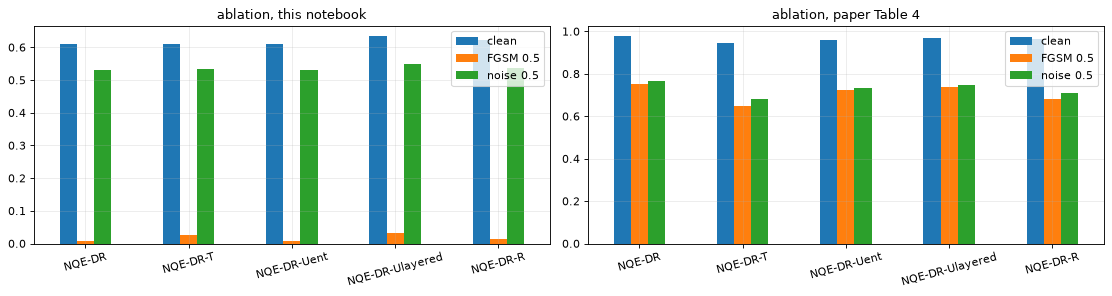

In [25]:
ABL = {}
t0 = time.time()
for enc in ["NQE-DR", "NQE-DR-T", "NQE-DR-Uent", "NQE-DR-Ulayered", "NQE-DR-R"]:
    lam = (0.0, 0.0) if enc == "NQE-DR-R" else (LAM1, LAM2)
    ABL[enc] = [run_one("circle", enc, s, lam1=lam[0], lam2=lam[1], eps_list=EPS_MNIST) for s in range(N_SEEDS)]
print(f"ablation: {(time.time() - t0) / 60:.1f} min")
A_ours = pd.DataFrame({e: row9(ABL[e]) for e in ABL}, index=cols).T
A_paper = pd.DataFrame({e: [PAPER_T4[e]["clean"]] + [PAPER_T4[e]["noise"][k] for k in EPS_MNIST] + [PAPER_T4[e]["fgsm"][k] for k in EPS_MNIST] for e in ABL}, index=cols).T
print("this notebook:"); print(A_ours.round(3).to_string()); print("\npaper Table 4:"); print(A_paper.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
A_ours[["clean", "FGSM 0.5", "noise 0.5"]].plot.bar(ax=ax[0]); ax[0].set_title("ablation, this notebook"); ax[0].tick_params(axis="x", rotation=15)
A_paper[["clean", "FGSM 0.5", "noise 0.5"]].plot.bar(ax=ax[1]); ax[1].set_title("ablation, paper Table 4"); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## 10. Why is the Circle accuracy not reached? A sensitivity study

With one block, NQE-DR on the 2-feature Circle problem has only **2 trainable parameters** and the model output is a degree-one trigonometric polynomial in each encoded angle. The study below varies the two things the paper leaves open (input scaling and the number of blocks, i.e. data re-uploading as in the authors' `n_layer = 3`) for NQE-DR and AE and reports clean test accuracy. The grid is a diagnostic, not a tuned result: no configuration is used elsewhere in the notebook.

In [26]:
c_raw = RAW["circle"]; n_fit = split_val(c_raw["n_train"])
Xc_fit, Xc_val, Xc_te = c_raw["X"][:n_fit], c_raw["X"][n_fit:c_raw["n_train"]], c_raw["X"][c_raw["n_train"]:]
mm = MinMaxScaler().fit(Xc_fit); zs = StandardScaler().fit(Xc_fit)
VARIANTS = {"MinMax [0,1] (paper text)": lambda a: np.clip(mm.transform(a), 0, 1),
            "MinMax [0,2*pi] (train_nqedr.py)": lambda a: 2 * np.pi * np.clip(mm.transform(a), 0, 1),
            "z-score": lambda a: zs.transform(a)}
yfit_c, yval_c, yte_c = [torch.tensor(c_raw["y"][s]).double() for s in (slice(0, n_fit), slice(n_fit, c_raw["n_train"]), slice(c_raw["n_train"], None))]
rows = []
t0 = time.time()
for vname, fn in VARIANTS.items():
    xs = [torch.tensor(fn(a)) for a in (Xc_fit, Xc_val, Xc_te)]
    for L in [1, 3]:
        for enc in ["NQE-DR", "AE"]:
            accs = []
            for s in range(SENS_SEEDS):
                m = Model(enc, 2, layers=L, seed=SEED + s)
                train(m, xs[0], yfit_c, xs[1], yval_c, LAM1, LAM2, SENS_EPOCHS, lr=LR, seed=SEED + s)
                accs.append(accuracy(m, xs[2], yte_c))
            rows.append(dict(input_scaling=vname, blocks=L, encoding=enc, test_acc=np.mean(accs), params=m.n_params()))
SENS = pd.DataFrame(rows)
print(f"sensitivity study: {time.time() - t0:.0f} s")
print(SENS.pivot_table(index=["input_scaling", "blocks"], columns="encoding", values="test_acc").round(3).to_string())
print("\npaper: Circle NQE-DR 0.978, AE 0.930")

# Exact ceiling of the paper's one-block circuit on the Circle training data: grid over BOTH trainable angles (no optimiser involved)
grid = torch.linspace(0, 2 * math.pi, 41)
xs_fit = torch.tensor(VARIANTS["MinMax [0,1] (paper text)"](Xc_fit))
for enc in ["NQE-DR", "AE"]:
    m = Model(enc, 2, seed=0); best = (0.0, None)
    for a in grid:
        for b in grid:
            with torch.no_grad():
                m.phi.copy_(torch.stack([a, b]).reshape(m.phi.shape))
            acc = accuracy(m, xs_fit, yfit_c)
            if acc > best[0]:
                best = (acc, (round(float(a), 2), round(float(b), 2)))
    print(f"{enc}: best training accuracy over a 41 x 41 grid of (phi_1, phi_2) = {best[0]:.3f} at {best[1]}  (2 qubits, 2 trainable parameters)")

sensitivity study: 272 s
encoding                                    AE  NQE-DR
input_scaling                    blocks               
MinMax [0,1] (paper text)        1       0.595   0.608
                                 3       0.652   0.680
MinMax [0,2*pi] (train_nqedr.py) 1       0.748   0.672
                                 3       0.775   0.753
z-score                          1       0.692   0.602
                                 3       0.707   0.757

paper: Circle NQE-DR 0.978, AE 0.930


NQE-DR: best training accuracy over a 41 x 41 grid of (phi_1, phi_2) = 0.621 at (0.94, 0.0)  (2 qubits, 2 trainable parameters)


AE: best training accuracy over a 41 x 41 grid of (phi_1, phi_2) = 0.636 at (1.41, 0.79)  (2 qubits, 2 trainable parameters)


### Optional: the 5-fold cross-validation behind `lambda1 = 0.01`, `lambda2 = 0.2`

The paper picks the regularisation strengths by 5-fold cross-validation on a grid; the authors' grid is `lambda1 in {0.001, 0.01, 0.05, 0.1, 0.2}`, `lambda2 in {0.1, 0.2, 0.3, 0.5, 0.7}`. A reduced 3-fold search on Breast Cancer is run only in the full mode (it multiplies the cost by 27); all experiments above use the paper's values either way.

In [27]:
if RUN_CV:
    d = DS["breast_cancer"]
    xall = torch.cat([d["xfit"], d["xva"]]); yall = torch.cat([d["yfit"], d["yva"]])
    grid1, grid2 = [0.001, 0.01, 0.1], [0.1, 0.2, 0.5]
    cv = pd.DataFrame(index=[f"lam1={a}" for a in grid1], columns=[f"lam2={b}" for b in grid2], dtype=float)
    for a in grid1:
        for b in grid2:
            sc = []
            for tr, va in KFold(3, shuffle=True, random_state=SEED).split(xall.numpy()):
                m = Model("NQE-DR", d["d"], seed=SEED)
                train(m, xall[tr], yall[tr], xall[va], yall[va], a, b, 60, lr=LR, seed=SEED)
                sc.append(accuracy(m, xall[va], yall[va]))
            cv.loc[f"lam1={a}", f"lam2={b}"] = np.mean(sc)
    print("mean validation accuracy over 3 folds (Breast Cancer, NQE-DR, 60 epochs):"); print(cv.round(3).to_string())
    i, j = np.unravel_index(np.nanargmax(cv.values), cv.shape)
    print(f"\nbest cell: {cv.index[i]}, {cv.columns[j]} ({cv.values[i, j]:.3f}); paper value lam1=0.01, lam2=0.2 gives {cv.loc['lam1=0.01', 'lam2=0.2']:.3f}; "
          f"spread of the whole grid {np.nanmax(cv.values) - np.nanmin(cv.values):.3f}")
else:
    print("skipped in FAST_MODE (set FAST_MODE = False)")

mean validation accuracy over 3 folds (Breast Cancer, NQE-DR, 60 epochs):
            lam2=0.1  lam2=0.2  lam2=0.5
lam1=0.001     0.737     0.735     0.725
lam1=0.01      0.730     0.727     0.722
lam1=0.1       0.715     0.715     0.715

best cell: lam1=0.001, lam2=0.1 (0.737); paper value lam1=0.01, lam2=0.2 gives 0.727; spread of the whole grid 0.022


## 11. Side by side with the paper, claim by claim

Rule (from the project brief): a value is **reproduced** if it is within 2 accuracy points (0.02) of the paper, **not reached** if lower by more, **exceeded** if higher by more. Ordering claims are checked directly. Where the notebook cannot test a claim the verdict is **cannot be checked**.

In [28]:
def verdict(nb, paper, tol=0.02):
    return "reproduced" if abs(nb - paper) <= tol else ("not reached" if nb < paper else "exceeded")

V = []
def add(claim, paper, nb, verdict_text):
    V.append(dict(claim=claim, paper=paper, notebook=nb, verdict=verdict_text))

# Table 1 clean accuracies
for dname in ["circle", "gaussian", "breast_cancer"]:
    for enc in ENC4:
        nb = np.mean([x["clean"] for x in MAIN[(dname, enc)]])
        add(f"T1 clean accuracy {enc} on {dname}", PAPER_T1[dname][enc], round(nb, 3), verdict(nb, PAPER_T1[dname][enc]))
for dname in ["circle", "gaussian", "breast_cancer"]:
    ours = {e: np.mean([x["clean"] for x in MAIN[(dname, e)]]) for e in ENC4}
    add(f"T1 NQE-DR is the most accurate encoding on {dname}", True, ours["NQE-DR"] >= max(ours[e] for e in ENC4[1:]),
        "reproduced" if ours["NQE-DR"] >= max(ours[e] for e in ENC4[1:]) else "not reached")
# Table 2 text claims
for dname, kind, eps, e_ in [("breast_cancer", "noise", 1.0, "NQE-DR"), ("breast_cancer", "fgsm", 1.0, "NQE-DR"), ("circle", "noise", 1.0, "NQE-DR"), ("gaussian", "fgsm", 1.0, "NQE-DR"),
                             ("gaussian", "fgsm", 1.0, "HEE"), ("gaussian", "fgsm", 1.0, "AE"), ("gaussian", "fgsm", 1.0, "AmE")]:
    nb = curve(dname, e_, kind)[EPS_LEVELS.index(eps)]; p = PAPER_T2[dname][kind][eps][e_]
    add(f"T2 {kind} strength {eps}, {e_}, {dname}", p, round(nb, 3), verdict(nb, p))
nq = np.mean([abs(curve(dn, "NQE-DR", k) - np.array([PAPER_T2[dn][k][e]["NQE-DR"] for e in EPS_LEVELS])).mean() for dn in ["circle", "gaussian", "breast_cancer"] for k in ["noise", "fgsm"]])
add("T2 mean |notebook - paper| over all 60 NQE-DR cells", 0.0, round(nq, 3), "reproduced" if nq <= 0.02 else "not reached (curves differ)")
frac_p = np.mean([PAPER_T2[dn][k][e]["NQE-DR"] >= max(PAPER_T2[dn][k][e][x] for x in ENC4[1:]) for dn in PAPER_T2 for k in ["noise", "fgsm"] for e in EPS_LEVELS])
frac_n = np.mean([curve(dn, "NQE-DR", k)[i] >= max(curve(dn, x, k)[i] for x in ENC4[1:]) - 1e-12 for dn in PAPER_T2 for k in ["noise", "fgsm"] for i in range(len(EPS_LEVELS))])
add("T2 fraction of cells in which NQE-DR is best", round(frac_p, 2), round(frac_n, 2), "reproduced" if frac_n >= frac_p - 0.2 else "not reached")
# Fig 7
lowest = LIP.pivot(index="encoding", columns="dataset", values="lipschitz").idxmin()
add("Fig7 NQE-DR has the lowest Lipschitz value (data sets where it does)", "3/3", f"{int((lowest == 'NQE-DR').sum())}/3", "reproduced" if (lowest == "NQE-DR").all() else "not reached")
add("Fig7 NQE-DR Lipschitz magnitude", PAPER_LIPSCHITZ_NQEDR, round(float(LIP[LIP.encoding == "NQE-DR"].lipschitz.mean()), 3), "cannot be checked (scale of the estimate is not defined in the paper)")
# Fig 8
add("Fig8 Lipschitz value stays 'substantial' for n<=12, d<=8 (smallest / largest value)", "qualitative", f"{SCALE.values.min():.3f} / {SCALE.values.max():.3f}", "cannot be checked ('substantial' has no numeric threshold; values stay positive)")
fac = float(SCALE.iloc[0].mean() / SCALE.iloc[-1].mean())
add("Fig8 decay of the Lipschitz value with n and d (Spearman with n, d)", "decays with both", f"{rho_n:+.2f}, {rho_d:+.2f}; mean over d falls by x{fac:.1f} from n={SCALE_NS[0]} to n={SCALE_NS[-1]}",
    "reproduced (direction)" if (rho_n < 0 and rho_d < 0) else "not reached")
# Table 3
for e in ["NQE-DR", "DRU", "AE"]:
    add(f"T3 MNIST clean accuracy {e}", PAPER_T3[e]["clean"], round(T3_ours.loc[e, "clean"], 3), verdict(T3_ours.loc[e, "clean"], PAPER_T3[e]["clean"]))
for c, k, eps in [("FGSM 0.5", "fgsm", 0.5), ("noise 0.5", "noise", 0.5)]:
    add(f"T3 MNIST NQE-DR {c}", PAPER_T3["NQE-DR"][k][eps], round(T3_ours.loc["NQE-DR", c], 3), verdict(T3_ours.loc["NQE-DR", c], PAPER_T3["NQE-DR"][k][eps]))
add("T3 NQE-DR best of six encodings (columns, of 9)", f"{best_p_t3}/9", f"{int(sum(T3_ours.loc['NQE-DR', c] >= T3_ours.loc[ENC6[1:], c].max() - 1e-12 for c in cols))}/9",
    "reproduced" if sum(T3_ours.loc['NQE-DR', c] >= T3_ours.loc[ENC6[1:], c].max() - 1e-12 for c in cols) >= 7 else "not reached")
# Table 4
add("T4 full model clean accuracy on Circle", PAPER_T4["NQE-DR"]["clean"], round(A_ours.loc["NQE-DR", "clean"], 3), verdict(A_ours.loc["NQE-DR", "clean"], PAPER_T4["NQE-DR"]["clean"]))
add("T4 full model FGSM 0.5 on Circle", PAPER_T4["NQE-DR"]["fgsm"][0.5], round(A_ours.loc["NQE-DR", "FGSM 0.5"], 3), verdict(A_ours.loc["NQE-DR", "FGSM 0.5"], PAPER_T4["NQE-DR"]["fgsm"][0.5]))
for v in ["NQE-DR-T", "NQE-DR-Uent", "NQE-DR-Ulayered", "NQE-DR-R"]:
    d_nb = A_ours.loc["NQE-DR", "FGSM 0.5"] - A_ours.loc[v, "FGSM 0.5"]; d_p = PAPER_T4["NQE-DR"]["fgsm"][0.5] - PAPER_T4[v]["fgsm"][0.5]
    add(f"T4 full model beats {v} under FGSM 0.5 (accuracy difference)", round(d_p, 3), round(d_nb, 3), "reproduced" if d_nb > 0 else "not reached (ablation does not hurt here)")
# classical / regularisation reference
add("(extra) classical SVC-rbf on the same Circle inputs", "not in paper", round(CLASSICAL["circle"]["clean"]["SVC-rbf (same inputs)"], 3), "cannot be checked (no paper value)")
VERDICTS = pd.DataFrame(V)
pd.set_option("display.max_colwidth", 80, "display.width", 200)
print(VERDICTS.to_string(index=False))
print("\nverdict counts:"); print(VERDICTS.verdict.str.split(" \(").str[0].value_counts().to_string())

                                                                              claim            paper                                                 notebook                                                                          verdict
                                                 T1 clean accuracy NQE-DR on circle            0.978                                                    0.611                                                                      not reached
                                                    T1 clean accuracy HEE on circle            0.945                                                    0.611                                                                      not reached
                                                     T1 clean accuracy AE on circle             0.93                                                    0.611                                                                      not reached
                                            

## 12. Reading the paper critically

* **The architecture as printed has very little capacity for low-dimensional data.** On Circle the model has 2 qubits and 2 trainable angles. The exact grid search over those two angles and the sensitivity study in section 10 show that accuracies near the paper's 0.978 are out of reach for the circuit in Eq. 9 to 16 (the ceilings are printed there), and with 2 qubits AE, HEE and the "full" CNOT network are literally the same circuit, so the Table 1 differences between AE and HEE (0.930 vs 0.945) cannot come from the encodings. The reported numbers must come from a model that is richer than the one described (the authors' tensors `weights[n_layer, n_qubit, x_dim, x_dim]` point to data re-uploading with learned linear maps), but that model is not in the public repository.
* **The readout scale is a hidden hyper-parameter.** With the authors' linear link the cross-entropy drives every model to the majority class (section 4b); a scale of about 10 on the expectation value is needed for the circuits to train at all. It is not mentioned in the paper, yet changes accuracies by tens of points.
* **Input range and the sigmoid.** With features in `[0, 1]` the sigmoid only maps them to `[0.5, 0.73]` and the square to `[0.25, 0.53]`: the encoder uses a narrow slice of the Bloch sphere. The paper motivates the sigmoid as "normalisation", which suggests z-scored inputs were intended; the sensitivity study shows this does not rescue the 2-qubit Circle model either.
* **The FGSM strengths 0.1 to 1.0 on `[0, 1]` features** are very large (strength 1.0 can move every feature to the opposite end of its range after clipping). A white-box sign-gradient attack of that size drives most models to or below chance accuracy here (the attack pushes samples to the wrong side of the decision boundary; see the printed FGSM table in section 6, which includes a classical MLP for comparison). The paper's FGSM accuracies at the same strengths (0.5 to 0.75) are much higher, so its attack was probably weaker than the one defined in its Section 2.3 (another scaling of the step, or gradients taken after the transformation `T`). The random-noise curves are therefore the more comparable part of Table 2. The paper also gives no seed count or error bars; differences of 1 to 3 points between encodings need many seeds to be distinguishable.
* **Gradient regularisation and robustness are not independent of the attack.** Penalising `||grad_x f||` makes FGSM less effective by construction, which is a real effect but partly gradient masking; the paper evaluates no gradient-free or adaptive attack.
* **Lipschitz value.** A Lipschitz estimate of 9.5 is not attainable by an expectation value in `[-1, 1]` of this circuit with inputs in `[0, 1]` (its input gradient is bounded by a small constant); the paper does not define the scaling. We report our own number and only the ordering is comparable.
* **Baselines receive the same regularisers** in this reproduction (as the repository's data classes suggest), so the comparison isolates the encoding; if the paper's baselines were trained without regularisation, part of NQE-DR's reported advantage would come from the regulariser rather than the encoding.
* **Code availability.** The public repository cannot reproduce the results (missing `circuit.py`, a syntax error in the training script, no attack code). The data-availability statement is therefore only partly met.

## Exercises

1. Set `LAYERS = 3` in the configuration and rerun section 5. Which encodings profit from data re-uploading on Circle? Does the NQE-DR advantage in Table 1 appear?
2. Replace the MinMax scaling of the Circle by z-scores in the data cell and check how often the sigmoid saturates (plot a histogram of `x_sig` and `x_sqr`).
3. Train NQE-DR with `lambda2 = 0` and with `lambda1 = 0` separately. Which regulariser contributes more to the FGSM curve? Compare with the paper's claim that both are needed.
4. Add a PGD attack (10 FGSM steps of size `eps / 4`, projected to the `eps`-ball) to `evaluate` and compare with FGSM. Is the NQE-DR advantage preserved?
5. Increase the number of seeds to 10 and add standard-deviation bands to the curves of section 6. For which strengths are the encoding differences larger than one standard deviation?